# 02 Pre-experiment rule checks (no LLM calls)

Pre-experiment checks on the review rules: the published baseline (Chohlas-Wood 2026, arXiv 2611.03213), the risk score, the toy simulator and the standard errors for RQ3. No LLM calls.
Sections are numbered; letters mark parts of one check. Each section carries its own header (question, expected, method, result, mismatch, feeds, and options or open questions).
A mismatch with an expected figure is reported as a mismatch and never adjusted.

**Status: sections 1 to 5 run.**

| Section | Test | Parts |
|---|---|---|
| 1 | Baseline rules | a code version and how it was run, b main result: each rule, and the ordering, against the paper, c Appendix D.9 rule beside the main combined rule, d Figure 1 axis: budgets the rules were designed for, e weight column the code reads (HWGT/FYWGT vs the _OLD columns), f Table B1 of the paper: cause codes treated as detectable, g review model as coded: minutes, success probabilities, false flags, h stability across draw seeds and across two choices the paper does not state |
| 2 | Risk score by error source | a risk score from section 1, and the features from section 3, b ranking quality on the 616 (filed values), c ranking quality on agency errors, d the 301 that could not be rebuilt, e side-by-side table |
| 3 | Feature leakage | a feature list with source column, b one feature function for both filers, c check on the 151 filed at $0, d features that cannot be built from a filed application, and how training inputs differ from filed inputs |
| 4 | Toy simulator | a toy caseload and planted errors, b rules run, c sanity values: oracle and random order, d budgets, e undocumented-group flag priced both ways, f capture vs dollars remaining |
| 5 | Standard errors for RQ3 | a base rates from the 616, b standard error by n, c filer-specific vs pooled, with shrinkage, d proposed grid of n |

Sections 2, 3 and 5 read the 616 human-arm table from `01-data-checks` section 3. Section 2 calls the feature function that section 3 documents and tests (`snapqc.features`). Section 4 runs the rule code in `snapqc.queue_sim`; section 5 uses `snapqc.calibration`.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from snapqc.data import ROOT, results_dir

OUT = results_dir("02-rule-checks")
SEED = 20261114
rng = np.random.default_rng(SEED)

## 1. Baseline rules

- **Question:** Does the public code for Chohlas-Wood (2026), "Reducing SNAP Payment Errors at Lower Cost With AI: A Simulation Study" (arXiv 2611.03213), reproduce his ordering of review rules on FY2024: the combined rule (AI flags first, then risk score) beats risk score only?
- **Expected:** the paper's figures (quoted in 1b with page numbers). The claim tested, from the abstract: "risk-based review alone costs about seven times as much as combining AI flags with risk scores". From Section 3 (p. 9): "Combined review brings 26 of these 27 jurisdictions below the threshold, compared with 25 for risk-based review and 19 for AI-based review. [...] Among the 25 jurisdictions where both risk-based and combined review reach the target, combined review requires less spending on reviews in 22. At the median [...] the risk-based approach costs about 7 times as much as the combined approach."
- **Method:** the paper's simulation code is not public: its reference [9], github.com/giannella/snap_qc, is the Better Government Lab risk-model code (R) that the paper says it adapted (1a). So: clone that repository at a pinned commit; take its reconstructed FY2017-24 frame, its household-size strata, its 19 inputs and its engine settings; fit the risk score on FY2022-23 and score FY2024 (scikit-learn gradient-boosted trees, because xgboost and R cannot run here). Rebuild the four review rules from the paper's Section 2 and Appendices B to D in `src/snapqc/review_sim.py`, run them on the FY2024 file (48 states and DC, `HWGT`), and compare with every figure the paper reports.
- **Result:** the ordering reproduces. Of the 27 jurisdictions at or above 6% (the same 27 the paper names), combined review brings 26 below 6%, risk only 25, AI only 19 and the D.9 rule 27, exactly the paper's counts, and the jurisdictions not reached are the same ones as in its Figure 2. Combined review costs less than risk only in 25 of the 25 jurisdictions both reach; risk only costs a median 8.98 times as much (paper: 22 of 25, about 7). The rebuilt Figure 1 (1d) matches the paper's California and Massachusetts curves as read by eye from its plot: AI-only plateaus 5.06% and 9.36%, and at 1,000 hours risk only 4.52% and 5.66%, combined 3.56% and 5.34% (paper about 5.1, 9.4, 4.5, 5.7, 3.6 and 5.3). The result holds under three more draw seeds, and the reach counts hold under two choices the paper does not state (1h).
- **Mismatch:** (1) combined is cheaper in 25 of 25, not 22 of 25; the cheapest ratio here is 1.8-2.0, while the paper's Figure 2 shows risk only at or below combined in Alabama, Mississippi and Nevada, where our combined cost is much lower than the paper's. (2) Median cost ratio 8.98 (8.97-9.15 across seeds), paper about 7. (3) California's risk-only/combined ratio is 15.0, outside the paper's 2-11 for California and Massachusetts (Massachusetts: 1.73, close to the low end); California risk only/AI only is 14.2, paper about 10. (4) States where AI only costs less than combined: Arizona, Delaware, Mississippi, North Dakota, Texas here; the paper names Delaware, Mississippi, Nevada, Alabama and Arizona. (5) 6.6% of households fall outside the simulation sample, paper 9.5%. (6) Median within-state AUC of the risk score 0.752, paper 0.77. Not checked: whether the paper's own code would give the same; it is not public. The causes of (1) to (4) are not known. The two unstated choices tested in 1h do not close them: letting only above-tolerance households draw flags moves the median ratio from 8.98 to 19.97, further from the paper, and changing the category ranking leaves it at 8.98. One unverified guess: the paper reads costs off a grid of budgets, which would make ties in small states (its Alabama and Mississippi points coincide).
- **Feeds:** `rq.md` RQ2 (the baseline rule, and whether "combined beats risk score only" holds on FY2024) and RQ3 (what our rule is compared against).
- **Options:** (a) use `snapqc.review_sim` as the baseline rule, described as rebuilt from the paper because it reproduces the paper's reach counts, not-reached sets and Figure 1; (b) first ask the author for the simulation code, so the baseline is his code and not a rebuild; (c) install an OpenMP runtime (or R) so the risk score uses xgboost itself, which may close the AUC gap. Separately, part 1d bears on which budgets to test. Figure 1's axis runs to 60 minutes per household, but the combined rule crosses 6% at a median of 13.6 hours per 1,000 households (about 0.8 minutes each), and at 0.5, 1 and 2 minutes it beats risk only in all 27 jurisdictions. The D.9 rule behaves like risk only at these budgets: its PER is below the main combined rule's in none of the 27 jurisdictions at 0.5 to 10 minutes, and in 18 at 60 minutes.

In [2]:
import subprocess
import warnings

from sklearn.metrics import roc_auc_score

from snapqc import review_sim as rs

warnings.filterwarnings("ignore", message="Missing constructor")
SNAP_QC = ROOT / "third_party" / "snap_qc"
SNAP_QC_COMMIT = "c9b2e7f226ef8b09bf70d60371f9916b827b9416"  # main on 2026-11-14; the paper cites the repo "n.d."

### 1a. Code version and how it was run

The paper's reference [9] is "Eric Giannella. snap_qc: Code and data for modeling SNAP payment errors. https://github.com/giannella/snap_qc, n.d." Section 1 (p. 4): "we adapt the publicly available SNAP risk model code developed by Eric Giannella at the Better Government Lab (BGL) [...]. We retain its data preparation procedures and prediction model specification [...]. However, we train on a narrower set of years (FY2022–2023)."

So the public code is BGL's risk-model code (R), not the paper's simulation. The cell below clones it (1.2 GB, git-ignored), pins the commit, and searches it for any trace of the simulation. What is used from it:

- `additional_data/reg_model_data.rds`: BGL's munged frame, with reconstructed pre-review inputs for FY2017-19 and FY2022-24 (the output of "its data preparation procedures");
- from `INCL_find_inclusion_rules_by_hh_size_v2.R`: the household-size strata (1 / 2-3 / 4+), the 19 input variables, and the xgboost settings;
- from `additional_data/year_data.csv`: the tolerance by year ($48 FY2022, $54 FY2023, $56 FY2024).

What is not run: no R script (R is not installed here), and the xgboost engine itself (its macOS build needs an OpenMP runtime that is not installed). The risk score is fitted with scikit-learn's gradient-boosted trees at BGL's settings (`snapqc.review_sim.fit_risk`). The four review rules are coded from the paper's text in `snapqc.review_sim`.

In [3]:
if not (SNAP_QC / ".git").exists():
    subprocess.run(["git", "clone", "--quiet", "https://github.com/giannella/snap_qc", str(SNAP_QC)], check=True)
subprocess.run(["git", "-C", str(SNAP_QC), "checkout", "--quiet", SNAP_QC_COMMIT], check=True)


def git(*args):
    return subprocess.run(["git", "-C", str(SNAP_QC), *args], capture_output=True, text=True, check=True).stdout.strip()


rds = SNAP_QC / "additional_data" / "reg_model_data.rds"
mentions = git("grep", "-i", "-l", "-E", "chohlas|preauthori[sz]ation", "--", "*.R", "*.py", "*.md")
code_version = pd.Series({
    "repository": "https://github.com/giannella/snap_qc",
    "commit": git("rev-parse", "HEAD"),
    "commit date": git("log", "-1", "--format=%ad", "--date=iso"),
    "commits in history": git("rev-list", "--count", "HEAD"),
    "reg_model_data.rds sha256": subprocess.run(["shasum", "-a", "256", str(rds)], capture_output=True, text=True).stdout.split()[0],
    "files naming Chohlas or preauthorization": mentions.replace("\n", "; ") or "none",
    "risk engine used here": "scikit-learn HistGradientBoostingClassifier (xgboost not loadable: no OpenMP runtime)",
    "simulation code": "not public; rebuilt from the paper text in src/snapqc/review_sim.py",
})
code_version.to_csv(OUT / "1a-code-version.csv", header=["value"])
code_version

repository                                               https://github.com/giannella/snap_qc
commit                                               c9b2e7f226ef8b09bf70d60371f9916b827b9416
commit date                                                         2026-11-12 20:11:39 -0800
commits in history                                                                        568
reg_model_data.rds sha256                   08e0e8259543daa7e9bd1c1e94d45580719cf91aa12dfc...
files naming Chohlas or preauthorization            methods/munging_drop_diagnosis/wa_rules.R
risk engine used here                       scikit-learn HistGradientBoostingClassifier (x...
simulation code                             not public; rebuilt from the paper text in src...
dtype: str

In [4]:
# extra columns, used in section 3: BGL's label for what its reconstruction changed, and its reconstructed amounts in review-year dollars
BGL_AMOUNT = {"earned": "rawearn_nominal", "unearned": "rawunearn_nominal", "rent": "rawrent_nominal", "util": "rawutil_nominal",
              "medical": "rawmedded_nominal", "depcare": "rawdepded_nominal", "child_support": "rawcsded_nominal"}
frame = rs.read_bgl_frame(rds, extra=["correctednotes", *BGL_AMOUNT.values()])
models = rs.fit_risk_models(frame, train_years=(2022, 2023))  # one model per household-size stratum; reused in section 2
risk = rs.fit_risk(frame, score_year=2024, models=models)
qc = rs.load_qc(2024)                                  # 48 contiguous states and DC
risk24 = qc.HHLDNO.map(risk)
in_sample = risk24.notna().to_numpy()
rank = rs.historical_category_order((2022, 2023))
sim = rs.Simulation(qc, in_sample, risk24.to_numpy(), rank, seed=SEED)

states = sorted(set(qc.STATENAME))
per0 = pd.Series({s: sim._curve(s, [])[1][0] for s in states})
above = per0[per0 >= rs.THRESHOLD].sort_values().index.tolist()
sample = pd.Series({
    "FY2024 households, 48 states + DC": len(qc),
    "in BGL frame": int(qc.HHLDNO.isin(frame.loc[frame.fiscal_year == 2024, "hhldno"]).sum()),
    "with complete inputs (scored, simulation sample)": int(in_sample.sum()),
    "share excluded": round(1 - in_sample.mean(), 3),
    "paper: share excluded (p. 4)": 0.095,
    "jurisdictions at or above 6% PER": len(above),
    "paper (p. 9)": 27,
})
sample

FY2024 households, 48 states + DC                   43299.000
in BGL frame                                        40497.000
with complete inputs (scored, simulation sample)    40455.000
share excluded                                          0.066
paper: share excluded (p. 4)                            0.095
jurisdictions at or above 6% PER                       27.000
paper (p. 9)                                           27.000
dtype: float64

### 1b. Main result: each rule, and the ordering, against the paper

For each of the jurisdictions at or above 6%, the lowest annual state review cost at which PER falls below 6%, with the best review scope chosen afterwards, as the paper does ("selecting the best-performing scope with the benefit of hindsight", p. 9). `inf` = not reached even when every review is done.

The paper's not-reached sets are read from its Figure 2 (p. 11; the "Not reached" column).

In [5]:
RULES = {"risk": "Risk only", "ai": "AI only", "combined": "Combined", "combined_d9": "Combined, risk order (D.9)"}
reach = pd.DataFrame({rule: {s: sim.reach_cost(s, rule)[0] for s in above} for rule in RULES})
scope = pd.DataFrame({rule: {s: sim.reach_cost(s, rule)[1] for s in above} for rule in RULES})
reach.insert(0, "PER before review", per0[above])
reach.round(4).to_csv(OUT / "1b-reach-cost-by-state.csv", index_label="state")
scope.to_csv(OUT / "1b-best-scope-by-state.csv", index_label="state")

y = (qc.AMTERR > rs.TOLERANCE[2024]).to_numpy()
auc = pd.Series({s: roc_auc_score(y[(qc.STATENAME == s).to_numpy() & in_sample],
                                   risk24[(qc.STATENAME == s).to_numpy() & in_sample]) for s in above})
auc.to_csv(OUT / "1b-auc-by-state.csv", index_label="state", header=["auc"])

reached = np.isfinite(reach[list(RULES)])
both = reached.risk & reached.combined
ratio = (reach.risk / reach.combined)[both]
not_reached = {r: sorted(reach.index[~reached[r]]) for r in RULES}
PAPER_NOT_REACHED = {
    "risk": ["District of Columbia", "Rhode Island"],
    "ai": ["Connecticut", "District of Columbia", "Illinois", "Massachusetts", "New Mexico", "Oklahoma", "Oregon",
           "Rhode Island"],
    "combined": ["District of Columbia"],
}
dc_needed = 1 - rs.THRESHOLD / per0["District of Columbia"]
dc_comb = 1 - min(per[-1] for _, per in sim.curves("District of Columbia", "combined").values()) / per0["District of Columbia"]
ai_cheaper = sorted(reach.index[reach.ai < reach.combined])

compare = pd.DataFrame([
    ("Jurisdictions at or above 6% PER", "27 (p. 9)", len(above)),
    ("Reached: combined", "26 (p. 9)", int(reached.combined.sum())),
    ("Reached: risk only", "25 (p. 9)", int(reached.risk.sum())),
    ("Reached: AI only", "19 (p. 9)", int(reached.ai.sum())),
    ("Reached: combined, risk order (D.9)", "27 (p. 28)", int(reached.combined_d9.sum())),
    ("Not reached: risk only", "DC, RI (Fig. 2)", ", ".join(not_reached["risk"])),
    ("Not reached: AI only", "CT, DC, IL, MA, NM, OK, OR, RI (Fig. 2)", ", ".join(not_reached["ai"])),
    ("Not reached: combined", "DC (Fig. 2)", ", ".join(not_reached["combined"])),
    ("Both risk only and combined reach", "25 (p. 9)", int(both.sum())),
    ("... combined cheaper", "22 of 25 (p. 9)", f"{int((ratio > 1).sum())} of {int(both.sum())}"),
    ("... median cost ratio, risk only / combined", "about 7 (p. 9; abstract)", round(ratio.median(), 2)),
    ("Cost ratio risk only / combined, California", "2-11, CA and MA (p. 9)", round(ratio["California"], 2)),
    ("Cost ratio risk only / combined, Massachusetts", "2-11, CA and MA (p. 9)", round(ratio["Massachusetts"], 2)),
    ("California: risk only cost / AI only cost", "about 10 (staff time, p. 9)", round(reach.risk["California"] / reach.ai["California"], 2)),
    ("States where AI only costs less than combined", "DE, MS, NV, AL, AZ (p. 10)", ", ".join(ai_cheaper)),
    ("DC: share of error dollars to remove to reach 6%", "about 57% (p. 10)", f"{dc_needed:.1%}"),
    ("DC: share combined removes at most", "55% (p. 10)", f"{dc_comb:.1%}"),
    ("Median within-state AUC of the risk score", "0.77 (App. D.7, p. 25)", round(auc.median(), 3)),
], columns=["figure", "paper", "this run"])
compare.to_csv(OUT / "1b-paper-vs-run.csv", index=False)
compare

,figure,paper,this run
0,Jurisdictions at or above 6% PER,27 (p. 9),27
1,Reached: combined,26 (p. 9),26
2,Reached: risk only,25 (p. 9),25
3,Reached: AI only,19 (p. 9),19
4,"Reached: combined, risk order (D.9)",27 (p. 28),27
5,Not reached: risk only,"DC, RI (Fig. 2)","District of Columbia, Rhode Island"
6,Not reached: AI only,"CT, DC, IL, MA, NM, OK, OR, RI (Fig. 2)","Connecticut, District of Columbia, Illinois, M..."
7,Not reached: combined,DC (Fig. 2),District of Columbia
8,Both risk only and combined reach,25 (p. 9),25
9,... combined cheaper,22 of 25 (p. 9),25 of 25


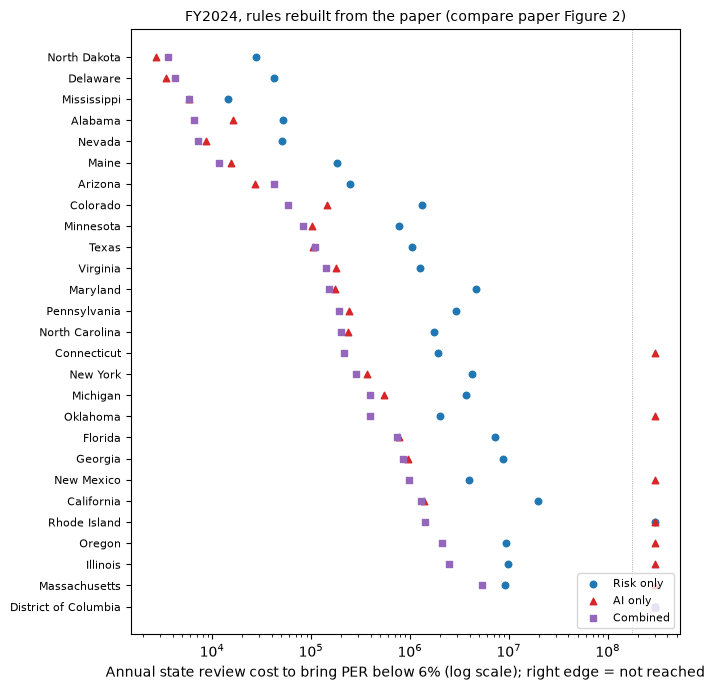

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
order = reach.combined.replace(np.inf, 1e9).sort_values(ascending=False).index
cap = 10 ** np.ceil(np.log10(reach[list(RULES)].replace(np.inf, np.nan).max().max())) * 3
for rule, marker, color in [("risk", "o", "tab:blue"), ("ai", "^", "tab:red"), ("combined", "s", "tab:purple")]:
    x = reach.loc[order, rule].replace(np.inf, cap)
    ax.scatter(x, range(len(order)), marker=marker, color=color, label=RULES[rule], s=22)
ax.set_xscale("log")
ax.axvline(cap / 1.7, color="grey", lw=0.5, ls=":")
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_xlabel("Annual state review cost to bring PER below 6% (log scale); right edge = not reached")
ax.set_title("FY2024, rules rebuilt from the paper (compare paper Figure 2)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "1b-figure2-rebuilt.svg")

### 1c. Appendix D.9 rule beside the main combined rule

Paper, Appendix D.9 (p. 28): "The alternative brings 27 jurisdictions below the threshold, compared with 26 under the main approach. It can reach the target in the District of Columbia, where the main approach stops short, but typically requires more review spending to reach the target elsewhere."

In [7]:
both_c = reached.combined & reached.combined_d9
d9 = pd.Series({
    "reached: main combined": int(reached.combined.sum()),
    "reached: D.9": int(reached.combined_d9.sum()),
    "D.9 reaches DC": bool(reached.combined_d9["District of Columbia"]),
    "D.9 cost in DC ($/year)": round(reach.combined_d9["District of Columbia"]),
    "both reach": int(both_c.sum()),
    "D.9 costs more than main": int((reach.combined_d9 > reach.combined)[both_c].sum()),
    "median cost ratio D.9 / main": round((reach.combined_d9 / reach.combined)[both_c].median(), 2),
    "D.9 costs less than risk only (both reach)": int((reach.combined_d9 < reach.risk)[reached.risk].sum()),
})
d9.to_csv(OUT / "1c-d9-vs-main.csv", header=["value"])
d9

reached: main combined                             26
reached: D.9                                       27
D.9 reaches DC                                   True
D.9 cost in DC ($/year)                       1989558
both reach                                         26
D.9 costs more than main                           26
median cost ratio D.9 / main                      5.7
D.9 costs less than risk only (both reach)         25
dtype: object

### 1d. Figure 1 axis: budgets the rules were designed for

Figure 1 (p. 10) plots PER against "Annual review hours per 1,000 scored households", from 0 to 1,000 (up to one hour per scored household a year). Our study's budgets are minutes per application. One minute per scored household a year is 16.7 hours per 1,000. The table shows each rule at 0.5, 1, 2 and 10 minutes, and the hours at which the combined rule reaches 6%.

In [8]:
BUDGET_MIN = [0.5, 1, 2, 10, 60]
grid = np.array(BUDGET_MIN) * 1000 / 60
env = {r: pd.DataFrame({s: sim.envelope(s, r, grid) for s in above}, index=BUDGET_MIN).T for r in RULES}
rows = []
for m in BUDGET_MIN:
    cap_ = {r: 1 - env[r][m] / per0[above] for r in RULES}
    rows.append({
        "minutes per scored household": m,
        "hours per 1,000": round(m * 1000 / 60, 1),
        **{f"median share of error $ removed: {RULES[r]}": round(cap_[r].median(), 3) for r in RULES},
        "states where combined PER < risk only PER": int((env["combined"][m] < env["risk"][m] - 1e-12).sum()),
        "states where combined PER < AI only PER": int((env["combined"][m] < env["ai"][m] - 1e-12).sum()),
        "states where D.9 PER < combined PER": int((env["combined_d9"][m] < env["combined"][m] - 1e-12).sum()),
        "states where D.9 PER < risk only PER": int((env["combined_d9"][m] < env["risk"][m] - 1e-12).sum()),
    })
budgets = pd.DataFrame(rows).set_index("minutes per scored household")
budgets.to_csv(OUT / "1d-capture-at-budgets.csv")

per_1000 = {s: qc.FYWGT[(qc.STATENAME == s).to_numpy() & in_sample].sum() / 1000 for s in above}
hours_to_reach = (reach.combined / rs.STATE_COST_PER_HOUR / pd.Series(per_1000)).replace(np.inf, np.nan)
print("hours per 1,000 scored households for combined to reach 6%: median",
      round(hours_to_reach.median(), 1), "| range", round(hours_to_reach.min(), 1), "to", round(hours_to_reach.max(), 1))
budgets.T

hours per 1,000 scored households for combined to reach 6%: median 13.6 | range 0.6 to 549.2


minutes per scored household,0.5,1.0,2.0,10.0,60.0
"hours per 1,000",8.300,16.700,33.300,166.700,1000.000
median share of error $ removed: Risk only,0.030,0.051,0.100,0.250,0.446
median share of error $ removed: AI only,0.130,0.200,0.325,0.335,0.335
median share of error $ removed: Combined,0.141,0.247,0.354,0.464,0.542
"median share of error $ removed: Combined, risk order (D.9)",0.038,0.067,0.120,0.318,0.559
states where combined PER < risk only PER,27.000,27.000,27.000,27.000,26.000
states where combined PER < AI only PER,18.000,26.000,26.000,27.000,27.000
states where D.9 PER < combined PER,0.000,0.000,0.000,0.000,18.000
states where D.9 PER < risk only PER,24.000,26.000,27.000,27.000,27.000


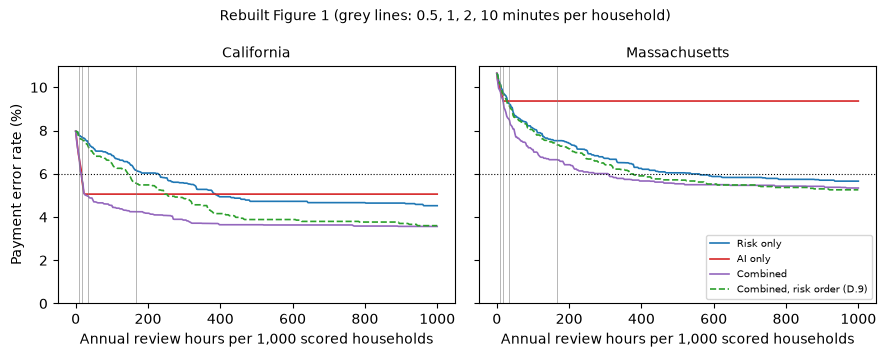

In [9]:
hours = np.linspace(0, 1000, 401)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, s in zip(axes, ["California", "Massachusetts"]):
    for rule, color in [("risk", "tab:blue"), ("ai", "tab:red"), ("combined", "tab:purple"), ("combined_d9", "tab:green")]:
        ax.plot(hours, 100 * sim.envelope(s, rule, hours), color=color, lw=1.2, label=RULES[rule],
                ls="--" if rule == "combined_d9" else "-")
    ax.axhline(6, color="black", ls=":", lw=0.8)
    for m in [0.5, 1, 2, 10]:
        ax.axvline(m * 1000 / 60, color="grey", lw=0.4)
    ax.set_title(s, fontsize=10)
    ax.set_xlabel("Annual review hours per 1,000 scored households")
axes[0].set_ylabel("Payment error rate (%)")
axes[0].set_ylim(0, None)
axes[1].legend(fontsize=7)
fig.suptitle("Rebuilt Figure 1 (grey lines: 0.5, 1, 2, 10 minutes per household)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "1d-figure1-rebuilt.svg")

### 1e. Weight column the code reads (HWGT/FYWGT vs the _OLD columns)

The paper does not name its weight column. The FY2024 file carries the revised weights (`HWGT`, `FYWGT`) and the earlier ones (`HWGT_OLD`, `FYWGT_OLD`). The set of jurisdictions at or above 6% tells them apart: the paper's Figure 2 lists 27 by name. BGL's frame carries its own `hwgt`, which equals neither column for all rows.

In [10]:
paper27 = sorted(PAPER_NOT_REACHED["ai"] + ["Alabama", "Arizona", "California", "Colorado", "Delaware", "Florida",
                                             "Georgia", "Maine", "Maryland", "Michigan", "Minnesota", "Mississippi",
                                             "Nevada", "New York", "North Carolina", "North Dakota", "Pennsylvania",
                                             "Texas", "Virginia"])
raw = pd.read_csv(ROOT / "data" / "raw" / "fy2024" / "qc_pub_fy2024.csv",
                  usecols=["HHLDNO", "STATENAME", "AMTERR", "RAWBEN", "HWGT", "HWGT_OLD"], low_memory=False)
raw = raw[~raw.STATENAME.isin(rs.OUTSIDE)]
weight_rows = []
for col in ["HWGT", "HWGT_OLD"]:
    g = raw.assign(e=raw.AMTERR * (raw.AMTERR > rs.TOLERANCE[2024]) * raw[col], b=raw.RAWBEN * raw[col]).groupby("STATENAME")[["e", "b"]].sum()
    per = g.e / g.b
    ours = set(per[per >= rs.THRESHOLD].index)
    weight_rows.append({"weight": col, "at or above 6%": len(ours),
                        "in ours, not in paper": ", ".join(sorted(ours - set(paper27))) or "none",
                        "in paper, not in ours": ", ".join(sorted(set(paper27) - ours)) or "none",
                        "PER Nevada": round(per["Nevada"], 4), "PER Indiana": round(per["Indiana"], 4)})
bgl = raw.merge(frame.loc[frame.fiscal_year == 2024, ["hhldno", "hwgt"]], left_on="HHLDNO", right_on="hhldno")
for row, col in zip(weight_rows, ["HWGT", "HWGT_OLD"]):
    row["BGL frame hwgt equal (share of FY2024 frame rows)"] = round(np.isclose(bgl.hwgt, bgl[col]).mean(), 3)
weights = pd.DataFrame(weight_rows).set_index("weight")
weights.to_csv(OUT / "1e-weights.csv")
weights

,at or above 6%,"in ours, not in paper","in paper, not in ours",PER Nevada,PER Indiana,BGL frame hwgt equal (share of FY2024 frame rows)
weight,,,,,,
HWGT,27,none,none,0.0614,0.0597,0.628
HWGT_OLD,27,Indiana,Nevada,0.0456,0.0635,0.000


### 1f. Table B1 of the paper: cause codes treated as detectable

Table B1 of the paper (p. 16), transcribed in `snapqc.review_sim.NOT_DETECTABLE`: causes 1, 3, 4, 7, 8, 26 and 99 are assumed not detectable; every other cause, and a missing cause, is assumed detectable. The FY2024 cause codes (`AGENCY1..9`) use the same code list. The table gives, for the simulation sample, the count of variances and the weighted error dollars by cause.

In [11]:
el = qc[[f"ELEMENT{i}" for i in range(1, 10)]].to_numpy(float)
ag = qc[[f"AGENCY{i}" for i in range(1, 10)]].to_numpy(float)
rec = ~np.isnan(el) & (qc.AMTERR.to_numpy()[:, None] > 0) & in_sample[:, None]
hh, slot = np.nonzero(rec)
assert len(hh) == len(sim.v) and (hh == sim.v.hh.to_numpy()).all()
causes = pd.DataFrame({"cause": ag[hh, slot], "dollars_w": sim.v.dollars.to_numpy() * qc.HWGT.to_numpy()[hh],
                       "detectable": sim.v.detectable.to_numpy()})
causes["cause"] = causes.cause.fillna(-1).astype(int).replace(-1, "missing").astype(str)
table_b1 = causes.groupby(["detectable", "cause"]).agg(variances=("cause", "size"), weighted_dollars=("dollars_w", "sum"))
table_b1["share of error $"] = (table_b1.weighted_dollars / table_b1.weighted_dollars.sum()).round(3)
table_b1.to_csv(OUT / "1f-table-b1-causes.csv")
print("share of FY2024 sample error dollars assumed detectable:",
      round(table_b1.loc[True, "weighted_dollars"].sum() / table_b1.weighted_dollars.sum(), 3))
table_b1

share of FY2024 sample error dollars assumed detectable: 0.548


variances  weighted_dollars  share of error $
detectable cause                                                 
False      1             2590      1.912390e+09             0.257
           26            5118      5.083765e+08             0.068
           3              387      3.748839e+08             0.050
           4             1155      4.408646e+08             0.059
           7               38      6.757537e+06             0.001
           8               42      8.752265e+06             0.001
           99             364      1.144187e+08             0.015
True       10            1204      5.200935e+08             0.070
           12            2239      1.393437e+09             0.187
           14             654      3.372302e+08             0.045
           15             337      1.495370e+08             0.020
           16             844      4.400371e+08             0.059
           17             228      5.048720e+07             0.007
           18             316      1.276891e+08             0.017
           19             750      7.462350e+07             0.010
           2             1101      3.802158e+08             0.051
           20             271      5.677276e+07             0.008
           21              27      6.116291e+06             0.001
           22             682      2.976803e+08             0.040
           23               6      2.823848e+06             0.000
           24               9      1.684287e+07             0.002
           25               9      1.575562e+06             0.000
           missing       2750      2.304845e+08             0.031

### 1g. Review model as coded: minutes, success probabilities, false flags

The paper's main assumptions, as coded, and checks on the flag model. Choices the paper does not state are listed with the choice made.

In [12]:
w = qc.HWGT.to_numpy()
real_flags = (sim.n_det * rs.FLAG_RECALL * w[:, None])[in_sample].sum()
false_flags = (sim.lam_hc * w[:, None])[in_sample].sum()
review_model = pd.DataFrame([
    ("Category check: minutes", rs.CAT_MINUTES, "Section 2.1"),
    ("Category check: probability it corrects all errors in the category", rs.CAT_SUCCESS, "Section 2.1"),
    ("Flag check: minutes", rs.FLAG_MINUTES, "Section 2.2"),
    ("Flag check: probability it corrects the flagged real error", rs.FLAG_SUCCESS, "Section 2.2"),
    ("Detectable error flagged with probability", rs.FLAG_RECALL, "Section 2.2"),
    ("False flags: Poisson, mean set per state and category so this share of flags is real", rs.FLAG_PRECISION, "Sections 2.2, 2.4"),
    ("Check: share of expected flags that are real, simulation sample", round(real_flags / (real_flags + false_flags), 4), "this run"),
    ("Check: expected flags per scored household", round((real_flags + false_flags) / w[in_sample].sum(), 3), "this run"),
    ("Draws per household", rs.N_DRAWS, "Section 2.4"),
    ("State labour cost, $ per hour", rs.STATE_COST_PER_HOUR, "Section 2.4"),
    ("Review scopes (top-k categories by FY2022-23 error dollars)", "k = 1..12", "Section 2.1"),
    ("Error split across a household's variances", "by AMOUNTn, else equal", "not stated in the paper"),
    ("Tolerance applied to", "the household's remaining error in each draw", "Section 2.4 says 'individual errors'; Appendix A counts 'case errors above the $56 reporting tolerance'"),
    ("Variances in households at or below the tolerance", "can draw flags (cost a flag check, correct no counted error); tested in 1h", "not stated in the paper"),
    ("Check: share of flaggable variances in households at or below the tolerance", round(float((qc.AMTERR.to_numpy()[sim.v.hh[sim.v.detectable].to_numpy()] <= rs.TOLERANCE[2024]).mean()), 3), "this run"),
    ("Category ranking: FY2022-23 error dollars counted", "all recorded error dollars, including households at or below that year's tolerance; tested in 1h", "not stated in the paper"),
    ("PER weight", "HWGT (see 1e)", "not stated in the paper"),
    ("Cost weight", "FYWGT = HWGT/12: one review per household a year", "not stated in the paper"),
    ("Category ranking ties", "national FY2022-23 order", "not stated in the paper"),
    ("D.9 flags outside the scope's categories", "not checked", "not stated in the paper"),
    ("AI-only flag order", "categories by FY2022-23 error dollars; the two other orders of Appendix D.8 (historical return, random) are not coded", "Section 2.2; Appendix D.8"),
    ("Risk engine", "scikit-learn gradient-boosted trees, BGL settings, no row subsampling", "paper: XGBoost"),
], columns=["item", "value", "source"])
review_model.to_csv(OUT / "1g-review-model.csv", index=False)
review_model

,item,value,source
0,Category check: minutes,10,Section 2.1
1,Category check: probability it corrects all er...,0.5,Section 2.1
2,Flag check: minutes,5,Section 2.2
3,Flag check: probability it corrects the flagge...,0.8,Section 2.2
4,Detectable error flagged with probability,0.8,Section 2.2
5,"False flags: Poisson, mean set per state and c...",0.8,"Sections 2.2, 2.4"
6,"Check: share of expected flags that are real, ...",0.8,this run
7,Check: expected flags per scored household,0.298,this run
8,Draws per household,200,Section 2.4
9,"State labour cost, $ per hour",30,Section 2.4


### 1h. Stability

The risk score here has no random element (no row subsampling), so its seed does not change the result. The flag and correction draws do. The headline figures under three more draw seeds:

In [13]:
stab = []
for seed in [1, 2, 3]:
    s_ = rs.Simulation(qc, in_sample, risk24.to_numpy(), rank, seed=seed)
    rc = pd.DataFrame({r: {s: s_.reach_cost(s, r)[0] for s in above} for r in RULES})
    b_ = np.isfinite(rc.risk) & np.isfinite(rc.combined)
    rt = (rc.risk / rc.combined)[b_]
    stab.append({"draw seed": seed, **{f"reached: {RULES[r]}": int(np.isfinite(rc[r]).sum()) for r in RULES},
                 "combined cheaper": f"{int((rt > 1).sum())} of {int(b_.sum())}", "median ratio": round(rt.median(), 2),
                 "lowest ratio": round(rt.min(), 2)})
stability = pd.DataFrame(stab).set_index("draw seed")
stability.to_csv(OUT / "1h-stability.csv")
stability

,reached: Risk only,reached: AI only,reached: Combined,"reached: Combined, risk order (D.9)",combined cheaper,median ratio,lowest ratio
draw seed,,,,,,,
1,25,19,26,27,25 of 25,8.97,2.00
2,25,19,26,27,25 of 25,9.15,1.82
3,25,19,26,27,25 of 25,9.09,1.82


Two choices the paper does not state (listed in 1g), each changed alone and then together, with the draw seed of 1b. First: whether a variance in a household whose error is at or below the tolerance can draw a flag. Second: whether the FY2022-23 category ranking counts error dollars of households at or below that year's tolerance.

In [14]:
rank_above = rs.historical_category_order((2022, 2023), above_tolerance_only=True)
CHOICES = {
    "as run in 1b": dict(rank=rank, flag_below_tolerance=True),
    "variances at or below the tolerance draw no flag": dict(rank=rank, flag_below_tolerance=False),
    "category ranking from above-tolerance dollars only": dict(rank=rank_above, flag_below_tolerance=True),
    "both changes": dict(rank=rank_above, flag_below_tolerance=False),
}
choice_rows = []
for label, kw in CHOICES.items():
    s_ = rs.Simulation(qc, in_sample, risk24.to_numpy(), kw["rank"], seed=SEED, flag_below_tolerance=kw["flag_below_tolerance"])
    rc = pd.DataFrame({r: {s: s_.reach_cost(s, r)[0] for s in above} for r in RULES})
    b_ = np.isfinite(rc.risk) & np.isfinite(rc.combined)
    rt = (rc.risk / rc.combined)[b_]
    choice_rows.append({
        "choice": label, **{f"reached: {RULES[r]}": int(np.isfinite(rc[r]).sum()) for r in RULES},
        "combined cheaper": f"{int((rt > 1).sum())} of {int(b_.sum())}", "median ratio": round(rt.median(), 2),
        "ratio, California": round(rt["California"], 2), "ratio, Massachusetts": round(rt["Massachusetts"], 2),
        "expected flags per scored household": round(float(((s_.n_det * rs.FLAG_RECALL + s_.lam_hc) * w[:, None])[in_sample].sum() / w[in_sample].sum()), 3),
        "AI only cheaper than combined": ", ".join(sorted(rc.index[rc.ai < rc.combined])),
    })
unstated = pd.DataFrame(choice_rows).set_index("choice")
unstated.to_csv(OUT / "1h-unstated-choices.csv")
unstated.T

choice,as run in 1b,variances at or below the tolerance draw no flag,category ranking from above-tolerance dollars only,both changes
reached: Risk only,25,25,25,25
reached: AI only,19,19,19,19
reached: Combined,26,26,26,26
"reached: Combined, risk order (D.9)",27,27,27,27
combined cheaper,25 of 25,25 of 25,25 of 25,25 of 25
median ratio,8.98,19.97,8.98,19.97
"ratio, California",14.97,31.35,14.66,30.71
"ratio, Massachusetts",1.73,1.99,1.73,1.99
expected flags per scored household,0.298,0.12,0.298,0.12
AI only cheaper than combined,"Arizona, Delaware, Mississippi, North Dakota, ...","Alabama, Arizona, California, Delaware, Missis...","Arizona, California, Delaware, Mississippi, No...","Alabama, Arizona, California, Delaware, Missis..."


## 2. Risk score by error source

- **Question:** How well does the risk score rank the human arm's client errors, compared with agency errors?
- **Expected:** None.
- **Method:** Score the 616 human-arm households (`results/01-data-checks/3d-human-arm.csv`) from their filed application, through the feature function of section 3 and the models of section 1. Score agency-error households with section 1's score. Ranking quality is the AUC against households in the same 41 states with no error above $56, pooled and within state, and the share of each group in the top 10% and 20% of its state's risk order. The 301 client-error households that could not be rebuilt have no filed application, so they are left out of the filed-value figures and scored separately with section 1's score.
- **Result:** the risk score ranks client errors that were filed as a wrong number about as well as it ranks agency errors, and it does not find the ones filed at $0. AUC against the 29,898 scored comparison households of the 41 states: the 616 from their filed application 0.694 (95% interval 0.678 to 0.714); of these, the 465 with a unique filed value 0.773 and the 151 filed at $0 0.451 (0.412 to 0.490), below 0.5. Agency-error households (2,060, of which 1,916 scored) 0.755 with section 1's score. In the top 20% of their state's risk order: 43% of the 465, 7% of the 151, 44% of agency-error households. The 301 that could not be rebuilt (221 with a score) have AUC 0.704 with section 1's score. Within-state and weighted figures tell the same story (2e).
- **Mismatch:** no expected figure was set. Three things to read with the result. (1) The score depends on which inputs it is given: for the 616, 0.694 from the filed application, 0.716 from BGL's frame (section 1's score) and 0.615 from QC-verified amounts; for agency errors 0.755 from BGL's frame and 0.680 from QC-verified amounts. (2) The two scores agree on the 465 (0.773 both) and differ on the 151 (0.451 filed, 0.541 section 1), where BGL's reconstructed amount is within $5 of the $0 filed value in 98 of 151 households (part 3d). (3) Not every household has a section 1 score: 614 of the 616, 221 of the 301 and 1,916 of the 2,060 agency-error households.
- **Feeds:** `rq.md` RQ2 (whether "risk score only" is a fair comparison on client errors).
- **Open questions:** (a) whether "risk score only" is reported for all client errors together or with the errors filed at $0 shown apart, since it ranks them below chance; (b) which inputs comparison and agency-error households are scored on in the caseload simulation: BGL's frame, as in section 1, or the feature function on QC-verified amounts; (c) whether the 301 enter RQ2 with section 1's score or are left out.

### 2a. Risk score from section 1, and the features from section 3

Three scores per household, all from the three models fitted in section 1 (FY2022-23):

- **section 1 score:** the inputs are the rows of BGL's frame, as in section 1;
- **QC-verified application:** the inputs are built by `snapqc.features.bgl_features` from the amounts QC verified;
- **filed application** (the 616 only): the same function, on the application with the amount in error replaced by the filed value.

Check first: on FY2024 households that BGL's reconstruction left unchanged, the function's score must equal section 1's score.

In [15]:
from snapqc import features as ft
from snapqc.data import SINGLE_SUA_STATES, load_fy2024, per_variance

full = load_fy2024()
c49 = full[~full.STATENAME.isin(rs.OUTSIDE)]  # 48 contiguous states and DC, every column
tables = ft.load_tables(SNAP_QC)
app_qc = ft.application_from_qc(c49)  # every amount as QC verified it
X_verified = ft.bgl_features(app_qc, tables)

arm = pd.read_csv(ROOT / "results" / "01-data-checks" / "3d-human-arm.csv", index_col="row")
rebuild = pd.read_csv(ROOT / "results" / "01-data-checks" / "3-rebuild.csv", index_col="row")
assert len(arm) == 616 and int(arm.in_151.sum()) == 151 and len(rebuild) == 917
app_filed = ft.file_amounts(app_qc.loc[arm.index], arm.amount, arm.filed_value, arm.element)
X_filed = ft.bgl_features(app_filed, tables)

score = pd.DataFrame({
    "section 1 score": c49.HHLDNO.map(risk),
    "QC-verified application": rs.score_risk(models, X_verified, app_qc["size"]),
})
score_filed = rs.score_risk(models, X_filed, app_filed["size"])

note24 = frame.loc[frame.fiscal_year == 2024].set_index("hhldno").correctednotes
unchanged = c49.HHLDNO.map(note24).eq("no_change") & score["section 1 score"].notna()
gap = (score["QC-verified application"] - score["section 1 score"])[unchanged].abs()
pd.Series({
    "FY2024 households, 48 states and DC": len(c49),
    "with a section 1 score": int(score["section 1 score"].notna().sum()),
    "left unchanged by BGL's reconstruction, with a score": int(unchanged.sum()),
    "  function score equals section 1 score (within 1e-9)": int((gap < 1e-9).sum()),
    "  largest difference": float(gap.max()),
    "human arm": len(arm),
    "  with a filed-application score": int(score_filed.notna().sum()),
    "  with a section 1 score": int(score.loc[arm.index, "section 1 score"].notna().sum()),
}).to_frame("value")

,value
"FY2024 households, 48 states and DC",43299.000000
with a section 1 score,40455.000000
"left unchanged by BGL's reconstruction, with a score",24877.000000
function score equals section 1 score (within 1e-9),24795.000000
largest difference,0.178668
human arm,616.000000
with a filed-application score,616.000000
with a section 1 score,614.000000


Error source of each household in the 41 single-row-SUA states (the states of the human arm). "Agency errors only": error above $56 and no variance with a client cause (causes 1, 2, 3, 4, 7). Comparison households: no error above $56, with a section 1 score.

In [16]:
in41 = c49.STATENAME.isin(SINGLE_SUA_STATES)
over = c49.AMTERR > rs.TOLERANCE[2024]
causes = c49[per_variance("AGENCY")]
client = causes.isin([1, 2, 3, 4, 7]).any(axis=1)
SOURCES = ["human arm: unique filed value (465)", "human arm: filed at $0 (151)", "client error, not rebuilt (301)",
           "client error, outside the 917", "agency errors only", "no cause recorded"]
source = pd.Series("no error above $56", index=c49.index)
source[over & client] = "client error, outside the 917"
source[over & ~client & causes.notna().any(axis=1)] = "agency errors only"
source[over & ~causes.notna().any(axis=1)] = "no cause recorded"
source[rebuild.index.difference(arm.index)] = "client error, not rebuilt (301)"
source[arm.index[~arm.in_151]] = "human arm: unique filed value (465)"
source[arm.index[arm.in_151]] = "human arm: filed at $0 (151)"
assert (over & in41)[rebuild.index].all()

negatives = in41 & ~over & score["section 1 score"].notna()
neg_score, neg_state, neg_w = score.loc[negatives, "section 1 score"].to_numpy(), c49.STATENAME[negatives].to_numpy(), c49.FYWGT[negatives].to_numpy()
# each state's scored households, sorted: the risk order a household is placed in
state_scores = {s: np.sort(g.to_numpy()) for s, g in score["section 1 score"].dropna().groupby(c49.STATENAME)}
pd.concat([source[in41].value_counts().rename("households, 41 states"),
           source[in41 & score["section 1 score"].notna()].value_counts().rename("with a section 1 score")], axis=1)

,"households, 41 states",with a section 1 score
no error above $56,31935,29898
agency errors only,2060,1916
"client error, outside the 917",1237,1143
human arm: unique filed value (465),465,463
"client error, not rebuilt (301)",301,221
human arm: filed at $0 (151),151,151
no cause recorded,10,3


In [17]:
from scipy.stats import rankdata

N_BOOT = 300


def within_state_auc(pos, pos_state, neg, neg_state):
    """AUC from pairs of one error household and one comparison household in the same state."""
    wins = pairs = 0.0
    for s in np.unique(pos_state):
        p, n_ = pos[pos_state == s], neg[neg_state == s]
        if len(p) and len(n_):
            r = rankdata(np.concatenate([p, n_]))
            wins += r[:len(p)].sum() - len(p) * (len(p) + 1) / 2
            pairs += len(p) * len(n_)
    return wins / pairs


def ranking_quality(pos_score, rows, boot_rng):
    """Ranking quality of error households (scores `pos_score`, on file rows `rows`) against the comparison households."""
    keep = np.isfinite(pos_score)
    p, st, w = pos_score[keep], c49.STATENAME[rows].to_numpy()[keep], c49.FYWGT[rows].to_numpy()[keep]
    dollars = (c49.AMTERR[rows] * c49.FYWGT[rows]).to_numpy()[keep]
    y, x = np.r_[np.ones(len(p)), np.zeros(len(neg_score))], np.r_[p, neg_score]
    boots = [roc_auc_score(y, np.r_[boot_rng.choice(p, len(p)), boot_rng.choice(neg_score, len(neg_score))]) for _ in range(N_BOOT)]
    pct = np.array([np.searchsorted(state_scores[s], v, side="right") / len(state_scores[s]) for s, v in zip(st, p)])
    return {
        "households": len(rows), "scored": int(keep.sum()),
        "AUC": round(roc_auc_score(y, x), 3),
        "AUC 95% interval": f"{np.quantile(boots, 0.025):.3f} to {np.quantile(boots, 0.975):.3f}",
        "AUC, weighted (FYWGT)": round(roc_auc_score(y, x, sample_weight=np.r_[w, neg_w]), 3),
        "AUC within state": round(within_state_auc(p, st, neg_score, neg_state), 3),
        "share in top 10% of state risk order": round(float((pct > 0.9).mean()), 3),
        "share in top 20%": round(float((pct > 0.8).mean()), 3),
        "share of the group's weighted error $ in top 20%": round(float(dollars[pct > 0.8].sum() / dollars.sum()), 3),
        "median score": round(float(np.median(p)), 3),
    }


print("comparison households:", int(negatives.sum()), "| median score", round(float(np.median(neg_score)), 3))

comparison households: 29898 | median score 0.072


### 2b. Ranking quality on the 616 (filed values)

The 616 scored from the filed application, with the two parts of the arm shown separately: the 465 with a unique filed value, and the 151 filed at $0 (issued the maximum benefit, income source not reported).

In [18]:
ARM_PARTS = {"human arm (616)": arm.index, "human arm: unique filed value (465)": arm.index[~arm.in_151],
             "human arm: filed at $0 (151)": arm.index[arm.in_151]}
rows_2b = {(name, "filed application"): ranking_quality(score_filed[rows].to_numpy(), rows, np.random.default_rng([SEED, 2, i]))
           for i, (name, rows) in enumerate(ARM_PARTS.items())}
quality_filed = pd.DataFrame(rows_2b).T
quality_filed

,,households,scored,AUC,AUC 95% interval,"AUC, weighted (FYWGT)",AUC within state,share in top 10% of state risk order,share in top 20%,share of the group's weighted error $ in top 20%,median score
human arm (616),filed application,616,616,0.694,0.678 to 0.714,0.684,0.686,0.19,0.339,0.33,0.137
human arm: unique filed value (465),filed application,465,465,0.773,0.758 to 0.789,0.767,0.763,0.237,0.428,0.464,0.163
human arm: filed at $0 (151),filed application,151,151,0.451,0.412 to 0.490,0.392,0.441,0.046,0.066,0.046,0.065


In [19]:
# The same 616 by fact group and by filed-value type (filed-application score).
by_group = pd.DataFrame({
    g: ranking_quality(score_filed[rows].to_numpy(), rows, np.random.default_rng([SEED, 22, i]))
    for i, (g, rows) in enumerate(list(arm.groupby("group").groups.items()) + list(arm.groupby("error_type").groups.items()))
}).T[["households", "AUC", "AUC 95% interval", "AUC within state", "share in top 20%", "median score"]]
by_group.to_csv(OUT / "2b-filed-by-group.csv", index_label="group or filed-value type")
by_group

,households,AUC,AUC 95% interval,AUC within state,share in top 20%,median score
earned,211,0.642,0.602 to 0.677,0.643,0.351,0.125
outside,15,0.889,0.842 to 0.935,0.879,0.733,0.232
shelter,191,0.764,0.739 to 0.789,0.748,0.361,0.156
unearned,131,0.657,0.611 to 0.692,0.648,0.275,0.126
utilities,68,0.688,0.643 to 0.733,0.673,0.279,0.115
empty,188,0.515,0.475 to 0.555,0.507,0.144,0.074
wrong number,428,0.773,0.754 to 0.789,0.762,0.425,0.161


### 2c. Ranking quality on agency errors

Households in the same 41 states with an error above $56 and no client-caused variance, scored with section 1's score (BGL's frame, which approximates the amounts the agency used). For an agency error the client's application is correct, so the QC-verified application is the filed application; its score is shown beside it. The last row repeats the first for all 48 states and DC, with that area's comparison households.

In [20]:
agency_rows = c49.index[in41 & (source == "agency errors only")]
rows_2c = {
    ("agency errors only", "section 1 score"): ranking_quality(score.loc[agency_rows, "section 1 score"].to_numpy(), agency_rows, np.random.default_rng([SEED, 3, 0])),
    ("agency errors only", "QC-verified application"): ranking_quality(score.loc[agency_rows, "QC-verified application"].to_numpy(), agency_rows, np.random.default_rng([SEED, 3, 1])),
}
quality_agency = pd.DataFrame(rows_2c).T

agency_all = c49.index[source == "agency errors only"]
neg_all = ~over & score["section 1 score"].notna()
pos_all = score.loc[agency_all, "section 1 score"].dropna().to_numpy()
auc_agency_49 = roc_auc_score(np.r_[np.ones(len(pos_all)), np.zeros(int(neg_all.sum()))], np.r_[pos_all, score.loc[neg_all, "section 1 score"].to_numpy()])
print(f"agency errors only, 48 states and DC: {len(agency_all)} households, {len(pos_all)} scored, AUC {auc_agency_49:.3f}")
quality_agency

agency errors only, 48 states and DC: 2652 households, 2454 scored, AUC 0.752


households scored    AUC  \
agency errors only section 1 score               2060   1916  0.755   
                   QC-verified application       2060   2060   0.68   

                                           AUC 95% interval  \
agency errors only section 1 score           0.745 to 0.765   
                   QC-verified application   0.668 to 0.690   

                                           AUC, weighted (FYWGT)  \
agency errors only section 1 score                         0.733   
                   QC-verified application                 0.654   

                                           AUC within state  \
agency errors only section 1 score                    0.747   
                   QC-verified application            0.667   

                                           share in top 10% of state risk order  \
agency errors only section 1 score                                        0.237   
                   QC-verified application                                0.177   

                                           share in top 20%  \
agency errors only section 1 score                    0.439   
                   QC-verified application            0.352   

                                           share of the group's weighted error $ in top 20%  \
agency errors only section 1 score                                                    0.432   
                   QC-verified application                                            0.332   

                                           median score  
agency errors only section 1 score                0.168  
                   QC-verified application        0.137

### 2d. The 301 that could not be rebuilt

The 917 client-error households less the 616. They have no filed value (the reasons are in `results/01-data-checks/3b-rebuild-outcomes.csv`), so they cannot be scored from a filed application. They are left out of the filed-value figures in 2b and scored here with section 1's score, where BGL's frame has them.

In [21]:
not_rebuilt = rebuild.index.difference(arm.index)
assert len(not_rebuilt) == 301
has_score = score.loc[not_rebuilt, "section 1 score"].notna()
why = pd.concat([rebuild.loc[not_rebuilt, "outcome"].value_counts().rename("households"),
                 rebuild.loc[not_rebuilt[has_score.to_numpy()], "outcome"].value_counts().rename("with a section 1 score")], axis=1).fillna(0).astype(int)
why.loc["total"] = why.sum()
why.to_csv(OUT / "2d-not-rebuilt.csv", index_label="outcome in 01-data-checks part 3b")
rows_2d = {("client error, not rebuilt (301)", "section 1 score"): ranking_quality(score.loc[not_rebuilt, "section 1 score"].to_numpy(), not_rebuilt, np.random.default_rng([SEED, 4]))}
why

,households,with a section 1 score
outcome,,
not unique: issued benefit at the maximum (net income zero),87,85
dropped: element is not a dollar amount,81,62
dropped: FSBEN differs from the QC-correct benefit,72,22
no inverse: no value reaches the issued benefit,27,27
not unique: shelter cap binding,14,14
dropped: calculator misses FSBEN (MFIP or SSI-CAP unit),9,0
not unique: shelter cost below half of income,6,6
not unique: issued benefit at the minimum,5,5
total,301,221


### 2e. Side-by-side table

Every error source in the 41 states, under each score it can be given. Comparison households are the same in every row.

In [22]:
rows_2e = dict(rows_2b)
for i, (name, rows) in enumerate(ARM_PARTS.items()):
    for j, col in enumerate(score.columns):
        rows_2e[(name, col)] = ranking_quality(score.loc[rows, col].to_numpy(), rows, np.random.default_rng([SEED, 5, i, j]))
rows_2e.update(rows_2d)
rows_2e.update(rows_2c)
for i, name in enumerate(["client error, outside the 917", "all errors above $56"]):
    rows = c49.index[in41 & ((source == name) if name != "all errors above $56" else over)]
    rows_2e[(name, "section 1 score")] = ranking_quality(score.loc[rows, "section 1 score"].to_numpy(), rows, np.random.default_rng([SEED, 6, i]))
side_by_side = pd.DataFrame(rows_2e).T
side_by_side.index.names = ["error source", "score"]
side_by_side.to_csv(OUT / "2e-risk-score-by-error-source.csv")
side_by_side

households scored  \
error source                        score                                       
human arm (616)                     filed application              616    616   
human arm: unique filed value (465) filed application              465    465   
human arm: filed at $0 (151)        filed application              151    151   
human arm (616)                     section 1 score                616    614   
                                    QC-verified application        616    616   
human arm: unique filed value (465) section 1 score                465    463   
                                    QC-verified application        465    465   
human arm: filed at $0 (151)        section 1 score                151    151   
                                    QC-verified application        151    151   
client error, not rebuilt (301)     section 1 score                301    221   
agency errors only                  section 1 score               2060   1916   
                                    QC-verified application       2060   2060   
client error, outside the 917       section 1 score               1237   1143   
all errors above $56                section 1 score               4224   3897   

                                                               AUC  \
error source                        score                            
human arm (616)                     filed application        0.694   
human arm: unique filed value (465) filed application        0.773   
human arm: filed at $0 (151)        filed application        0.451   
human arm (616)                     section 1 score          0.716   
                                    QC-verified application  0.615   
human arm: unique filed value (465) section 1 score          0.773   
                                    QC-verified application   0.61   
human arm: filed at $0 (151)        section 1 score          0.541   
                                    QC-verified application   0.63   
client error, not rebuilt (301)     section 1 score          0.704   
agency errors only                  section 1 score          0.755   
                                    QC-verified application   0.68   
client error, outside the 917       section 1 score          0.776   
all errors above $56                section 1 score          0.752   

                                                            AUC 95% interval  \
error source                        score                                      
human arm (616)                     filed application         0.678 to 0.714   
human arm: unique filed value (465) filed application         0.758 to 0.789   
human arm: filed at $0 (151)        filed application         0.412 to 0.490   
human arm (616)                     section 1 score           0.697 to 0.734   
                                    QC-verified application   0.593 to 0.637   
human arm: unique filed value (465) section 1 score           0.757 to 0.788   
                                    QC-verified application   0.583 to 0.637   
human arm: filed at $0 (151)        section 1 score           0.498 to 0.582   
                                    QC-verified application   0.588 to 0.672   
client error, not rebuilt (301)     section 1 score           0.674 to 0.735   
agency errors only                  section 1 score           0.745 to 0.765   
                                    QC-verified application   0.668 to 0.690   
client error, outside the 917       section 1 score           0.762 to 0.787   
all errors above $56                section 1 score           0.745 to 0.760   

                                                            AUC, weighted (FYWGT)  \
error source                        score                                           
human arm (616)                     filed application                       0.684   
human arm: unique filed value (465) filed application                       0.767   
human arm: filed at $

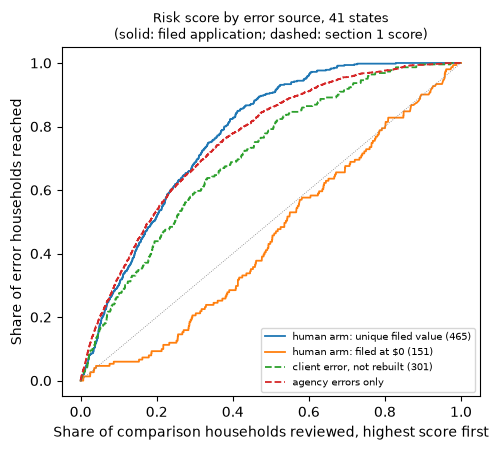

In [23]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5, 4.6))
curves = [("human arm: unique filed value (465)", score_filed[arm.index[~arm.in_151]].to_numpy(), "tab:blue", "-"),
          ("human arm: filed at $0 (151)", score_filed[arm.index[arm.in_151]].to_numpy(), "tab:orange", "-"),
          ("client error, not rebuilt (301)", score.loc[not_rebuilt, "section 1 score"].dropna().to_numpy(), "tab:green", "--"),
          ("agency errors only", score.loc[agency_rows, "section 1 score"].dropna().to_numpy(), "tab:red", "--")]
for label, p, color, ls in curves:
    fpr, tpr, _ = roc_curve(np.r_[np.ones(len(p)), np.zeros(len(neg_score))], np.r_[p, neg_score])
    ax.plot(fpr, tpr, color=color, ls=ls, lw=1.3, label=label)
ax.plot([0, 1], [0, 1], color="grey", lw=0.6, ls=":")
ax.set_xlabel("Share of comparison households reviewed, highest score first")
ax.set_ylabel("Share of error households reached")
ax.set_title("Risk score by error source, 41 states\n(solid: filed application; dashed: section 1 score)", fontsize=9)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "2e-roc-by-error-source.svg")

## 3. Feature leakage

- **Question:** Does every risk-score feature come from the filed application, through one function, for both filers?
- **Expected:** None. Pass means no feature of a human-arm household reads a QC-verified amount in the error group.
- **Method:** List each feature with its source column. Build features through one function in `src/snapqc/` (`snapqc.features.bgl_features`). Check the function against BGL's frame on households BGL left unchanged. Check the 151 households filed at $0: their income features must be $0. Change the QC-verified amount in the error group and confirm no feature of the filed application moves. Record what the model was trained on.
- **Result:** pass. One function, `snapqc.features.bgl_features`, builds the 19 inputs from an application table, and no other code computes them. On the 24,908 FY2024 households that BGL's reconstruction left unchanged it returns BGL's frame exactly for 18 features, and for 99.67% of households on the 19th (`count_divisible_by_100`; 82 households differ by 1). Changing the QC-verified amount in the error group moves no feature of the filed application for any of the 616; the same change moves the QC-verified features of 614. The builder reads 75 QC columns, none of them a total QC derives from the verified amounts or a review outcome. All 151 households filed at $0 have a $0 income feature for the group in error, $0 for each of its income types, and an implied benefit at the maximum. Of the 19 features, 5 come from the form alone, 10 from the form with published tables and the benefit formula, and 4 need an agency or state record (`expedited_i`, `months_since_cert_n`, `percent_abawd`, `bbce_state_i`).
- **Mismatch:** no expected figure was set. One difference between training and scoring is recorded in 3d: the model is trained neither on filed applications nor on QC-verified amounts but on BGL's frame, where the amounts of 98.5% of FY2022-23 error rows (8,345 of 8,469) and of 29.2% of rows without an error were moved by BGL's reconstruction, which uses the QC finding. `count_divisible_by_100` is counted over QC-verified amounts in training. For the human arm, BGL's reconstructed amount is within $5 of our filed value in 530 of 614 households (432 of 463 with a unique filed value, 98 of the 151), all 19 features agree in 171 of 614, and the two scores correlate 0.931.
- **Feeds:** `rq.md` RQ2 and RQ3 (leakage guard).
- **Open questions:** (a) for AI-filed applications, whether the four agency-record features are copied from the household's QC row (the same for both filers) or dropped and the model refitted; (b) whether to accept that the model is trained on BGL's reconstruction and scored on filed applications, or to refit it on inputs built by this function (FY2022-23 filed values would have to be rebuilt first); (c) how an AI filer's form maps to the 21 income types that `count_divisible_by_100` counts.

### 3a. Feature list with source column

The 19 inputs of the BGL model, the application fields each is computed from, and what else it needs. "Moves with" lists the fact groups whose filed amount changes the feature: each application amount is raised by $100 in turn on the 616 filed applications, and a feature is listed if it changes for any household.

In [24]:
FEATURE_FIELDS = {
    "HH_size_n": ["size"],
    "children_i": ["children"],
    "elderly_disabled_i": ["elderly_or_disabled"],
    "married": ["married"],
    "homeless": ["homeless"],
    "earned_by_hh_size": ["earned", "size"],
    "unearned_by_hh_size": ["unearned", "size"],
    "gross_by_hh_size": ["earned", "unearned", "size"],
    "shelter_expenses_by_hh_size": ["rent", "util", "size"],
    "utilities": ["util"],
    "medical_deductions": ["medical"],
    "total_deductions_by_hh_size": ["earned", "unearned", "rent", "util", "medical", "depcare", "child_support", "homeless_ded", "elderly_or_disabled", "size"],
    "rawben_rel_max": ["earned", "unearned", "rent", "util", "medical", "depcare", "child_support", "homeless_ded", "elderly_or_disabled", "size", "benmax", "min_ben"],
    "unc_rawben_rel_max": ["earned", "unearned", "rent", "util", "medical", "depcare", "child_support", "homeless_ded", "elderly_or_disabled", "size", "benmax"],
    "count_divisible_by_100": ["income by type (21 fields)", "earned", "unearned", "rent", "util", "medical", "depcare", "child_support", "homeless_ded"],
    "percent_abawd": ["n_abawd", "size"],
    "expedited_i": ["expedited"],
    "months_since_cert_n": ["months_since_cert"],
    "bbce_state_i": ["bbce_state"],
}
ALSO_NEEDS = {
    "earned_by_hh_size": "CPI", "unearned_by_hh_size": "CPI", "gross_by_hh_size": "CPI",
    "shelter_expenses_by_hh_size": "CPI; state utility standard", "utilities": "CPI; state utility standard",
    "medical_deductions": "CPI; state medical standard",
    "total_deductions_by_hh_size": "benefit formula; CPI; FY2026 standard deduction, shelter cap, utility and medical standards",
    "rawben_rel_max": "benefit formula; review-year standard deduction and shelter cap",
    "unc_rawben_rel_max": "benefit formula; review-year standard deduction and shelter cap",
    "count_divisible_by_100": "benefit formula (the deductions counted are computed)",
}
assert set(FEATURE_FIELDS) == set(rs.FEATURES)

FACT_GROUP_OF = {"earned": "earned", "unearned": "unearned", "rent": "shelter", "util": "utilities",
                 "medical": "outside (medical)", "depcare": "outside (dependent care)", "child_support": "outside (child support)"}
moves = {f: [] for f in rs.FEATURES}
for field, group in FACT_GROUP_OF.items():
    bumped = app_filed.copy()
    bumped[field] += 100
    if field in ("earned", "unearned"):  # the income type moves with its group total
        bumped["FSWAGES" if field == "earned" else "FSSOCSEC"] += 100
    changed = (ft.bgl_features(bumped, tables) - X_filed).abs().max() > 1e-9
    for f in changed.index[changed]:
        moves[f].append(group)

where_held = {k: v[1] for k, v in ft.APPLICATION_FIELDS.items()}
qc_source = {k: v[0] for k, v in ft.APPLICATION_FIELDS.items()}


def field_class(fields):
    """Who holds the fields. The homeless shelter deduction is listed apart: it is an agency decision, but only for homeless households."""
    held = {where_held.get(f, "application: income by type").split(":")[0] for f in fields if f != "homeless_ded"}
    held.discard("program table")
    return " + ".join(sorted(held))


feature_sources = pd.DataFrame({
    "application fields": {f: ", ".join(v) for f, v in FEATURE_FIELDS.items()},
    "QC file source": {f: "; ".join(qc_source.get(x, "FSWAGES ... FSFOSTER") for x in v if x not in ("benmax", "min_ben")) for f, v in FEATURE_FIELDS.items()},
    "held by": {f: field_class(v) for f, v in FEATURE_FIELDS.items()},
    "also needs": {f: ALSO_NEEDS.get(f, "") + ("; homeless shelter deduction if the agency granted one" if "homeless_ded" in FEATURE_FIELDS[f] else "") for f in FEATURE_FIELDS},
    "moves with the filed amount of": {f: ", ".join(moves[f]) or "none" for f in FEATURE_FIELDS},
}).reindex(rs.FEATURES)
feature_sources.to_csv(OUT / "3a-feature-sources.csv", index_label="feature")
feature_sources

,application fields,QC file source,held by,also needs,moves with the filed amount of
HH_size_n,size,FSUSIZE,application,,none
children_i,children,FSNKID > 0,application,,none
elderly_disabled_i,elderly_or_disabled,FSNELDER > 0 or FSNDIS > 0,application,,none
total_deductions_by_hh_size,"earned, unearned, rent, util, medical, depcare...",FSEARN; FSUNEARN; RENT; UTIL; FSMEDDED; FSDEPD...,application,benefit formula; CPI; FY2026 standard deductio...,"earned, unearned, shelter, utilities, outside ..."
expedited_i,expedited,EXPEDSER < 3,agency,,none
bbce_state_i,bbce_state,state share of CAT_ELIG >= 1 at least 0.5,state policy,,none
rawben_rel_max,"earned, unearned, rent, util, medical, depcare...",FSEARN; FSUNEARN; RENT; UTIL; FSMEDDED; FSDEPD...,application,benefit formula; review-year standard deductio...,"earned, unearned, shelter, utilities, outside ..."
medical_deductions,medical,FSMEDDED,application,CPI; state medical standard,outside (medical)
shelter_expenses_by_hh_size,"rent, util, size",RENT; UTIL; FSUSIZE,application,CPI; state utility standard,"shelter, utilities"
utilities,util,UTIL,application,CPI; state utility standard,utilities


### 3b. One feature function for both filers

`snapqc.features.bgl_features(application, tables)` is the only place the 19 inputs are computed. It takes an application table (one row per household, the fields of 3a) and the program tables. A human-filed application is the QC row with the filed value in place of the amount in error (`file_amounts`); an AI-filed application will be a table with the same columns.

Check 1: the function gives the inputs the model was trained on. On FY2024 households that BGL's reconstruction left unchanged (filed amounts = QC amounts), the function's output is compared with BGL's frame, feature by feature.

In [25]:
fr24 = frame[frame.fiscal_year == 2024].set_index("hhldno")
same_rows = c49.index[c49.HHLDNO.map(note24).eq("no_change")]
ours, theirs = X_verified.loc[same_rows], fr24.loc[c49.HHLDNO[same_rows], rs.FEATURES].set_axis(same_rows)
both_missing = ours.isna() & theirs.isna()
function_vs_frame = pd.DataFrame({
    "households": len(same_rows),
    "equal": ((ours - theirs).abs() < 1e-6).sum() + both_missing.sum(),
    "differ": ((ours - theirs).abs() >= 1e-6).sum(),
    "missing in one only": (ours.isna() ^ theirs.isna()).sum(),
    "largest difference": (ours - theirs).abs().max().round(4),
})
function_vs_frame["share equal"] = (function_vs_frame["equal"] / len(same_rows)).round(4)
function_vs_frame.to_csv(OUT / "3b-function-vs-frame.csv", index_label="feature")
function_vs_frame

,households,equal,differ,missing in one only,largest difference,share equal
HH_size_n,24908,24908,0,0,0.0,1.0000
children_i,24908,24908,0,0,0.0,1.0000
elderly_disabled_i,24908,24908,0,0,0.0,1.0000
total_deductions_by_hh_size,24908,24908,0,0,0.0,1.0000
expedited_i,24908,24908,0,0,0.0,1.0000
bbce_state_i,24908,24908,0,0,0.0,1.0000
rawben_rel_max,24908,24908,0,0,0.0,1.0000
medical_deductions,24908,24908,0,0,0.0,1.0000
shelter_expenses_by_hh_size,24908,24908,0,0,0.0,1.0000
utilities,24908,24908,0,0,0.0,1.0000


Check 2: no QC-verified amount in the error group reaches a feature of the filed application. The verified amount of the group in error (the group total, and the income type the error names, or every income type of the group for the 151) is changed by $777 in a copy of the QC rows, the filed application is rebuilt, and the features are recomputed. They must not move. The same change does move the features of the QC-verified application, which shows the test can fail.

In [26]:
GROUP_TOTAL = {"earned": "FSEARN", "unearned": "FSUNEARN", "rent": "RENT", "util": "UTIL", "medical": "FSMEDDED",
               "depcare": "FSDEPDED", "child_support": "FSCSEXP"}
tampered = c49.loc[arm.index].copy()
for i in arm.index:
    field = arm.amount[i]
    tampered.at[i, GROUP_TOTAL[field]] = (0 if pd.isna(tampered.at[i, GROUP_TOTAL[field]]) else tampered.at[i, GROUP_TOTAL[field]]) + 777
    if field in ("earned", "unearned"):
        types = ft.EARNED_TYPES if field == "earned" else ft.UNEARNED_TYPES
        named = ft.ELEMENT_TYPE[int(arm.element[i])]
        if named == "FSTANF" and c49.at[i, "FSTANF"] == 0 and c49.at[i, "FSGA"] > 0:
            named = "FSGA"
        for t in (types if arm.in_151[i] else [named]):
            if t in tampered:
                tampered.at[i, t] = (0 if pd.isna(tampered.at[i, t]) else tampered.at[i, t]) + 777
bbce = app_qc.groupby("state").bbce_state.first()
app_tampered = ft.application_from_qc(tampered, bbce=bbce)
X_filed_tampered = ft.bgl_features(ft.file_amounts(app_tampered, arm.amount, arm.filed_value, arm.element), tables)
X_verified_tampered = ft.bgl_features(app_tampered, tables)

moved_filed = (X_filed_tampered - X_filed).abs().max(axis=1) > 1e-9
moved_verified = (X_verified_tampered - X_verified.loc[arm.index]).abs().max(axis=1) > 1e-9
differs = (X_filed - X_verified.loc[arm.index]).abs().max(axis=1) > 1e-9
# The builder reads only the columns in ft.QC_COLUMNS_READ: with every other column of the QC rows removed, the output is the same.
only_read = c49.loc[arm.index, [col for col in ft.QC_COLUMNS_READ if col in c49]]
X_only_read = ft.bgl_features(ft.file_amounts(ft.application_from_qc(only_read, bbce=bbce), arm.amount, arm.filed_value, arm.element), tables)
derived = ["FSGRINC", "FSNETINC", "FSBEN", "FSSLTDED", "FSERNDED", "FSTOTDED", "FSSLTEXP", "RAWBEN", "BENFIX", "AMTERR", "STATUS"]
assert not set(derived) & set(ft.QC_COLUMNS_READ) and X_only_read.equals(X_filed)

leak_check = pd.Series({
    "human-arm households": len(arm),
    "QC file columns the application builder reads": len([col for col in ft.QC_COLUMNS_READ if col in c49]),
    "of which totals QC derives from the verified amounts (FSGRINC, FSNETINC, FSBEN, FSSLTDED, FSERNDED, FSTOTDED) or review outcomes": len(set(derived) & set(ft.QC_COLUMNS_READ)),
    "filed-application features that move when the verified amount is changed (must be 0)": int(moved_filed.sum()),
    "QC-verified-application features that move under the same change": int(moved_verified.sum()),
    "households whose filed features differ from their QC-verified features": int(differs.sum()),
    "households whose filed features equal their QC-verified features": int((~differs).sum()),
})
leak_check.to_csv(OUT / "3b-leak-check.csv", header=["households"])
assert moved_filed.sum() == 0
leak_check.to_frame("households")

,households
human-arm households,616
QC file columns the application builder reads,75
"of which totals QC derives from the verified amounts (FSGRINC, FSNETINC, FSBEN, FSSLTDED, FSERNDED, FSTOTDED) or review outcomes",0
filed-application features that move when the verified amount is changed (must be 0),0
QC-verified-application features that move under the same change,614
households whose filed features differ from their QC-verified features,616
households whose filed features equal their QC-verified features,0


### 3c. Check on the 151 filed at $0

For the 151, the group in error is filed at $0. Its income feature must be $0, every income type of that group must be $0 on the application, and the benefit the application implies must be the maximum.

In [27]:
z = arm.index[arm.in_151]
income_feature = np.where(arm.amount[z] == "earned", X_filed.loc[z, "earned_by_hh_size"], X_filed.loc[z, "unearned_by_hh_size"])
group_types = [ft.EARNED_TYPES if a == "earned" else ft.UNEARNED_TYPES for a in arm.amount[z]]
types_zero = np.array([(app_filed.loc[i, t] == 0).all() for i, t in zip(z, group_types)])
verified_feature = np.where(arm.amount[z] == "earned", X_verified.loc[z, "earned_by_hh_size"], X_verified.loc[z, "unearned_by_hh_size"])
check_151 = pd.Series({
    "households filed at $0": len(z),
    "income feature of the group in error is $0": int((income_feature == 0).sum()),
    "every income type of that group is $0 on the application": int(types_zero.sum()),
    "same feature from the QC-verified amount is above $0": int((verified_feature > 0).sum()),
    "gross income feature is $0 (no income in the other group either)": int((X_filed.loc[z, "gross_by_hh_size"] == 0).sum()),
    "implied benefit is the maximum (rawben_rel_max = 1)": int((X_filed.loc[z, "rawben_rel_max"] == 1).sum()),
})
check_151.to_csv(OUT / "3c-filed-at-zero.csv", header=["households"])
assert (income_feature == 0).all() and types_zero.all()
check_151.to_frame("households")

,households
households filed at $0,151
income feature of the group in error is $0,151
every income type of that group is $0 on the application,151
same feature from the QC-verified amount is above $0,151
gross income feature is $0 (no income in the other group either),133
implied benefit is the maximum (rawben_rel_max = 1),151


### 3d. Features that cannot be built from a filed application

First table: the 19 features by what holds their fields (from 3a). Features marked "agency" or "state policy" are not on a filed form: they come from the agency's own records, and are the same whoever filed. Features that need the benefit formula are computed here by the function from the filed amounts and the published tables, not read from the agency's determination. Four of those also read the homeless shelter deduction, an agency decision that applies to homeless households only (the last line counts them among the 616).

In [28]:
on_form = feature_sources[["held by", "also needs"]].copy()
on_form.insert(0, "from the filed form", np.select(
    [on_form["held by"].str.contains("agency|state policy"), on_form["also needs"] != ""],
    ["no: needs an agency or state record", "yes, with published tables (CPI, standards, benefit formula)"], default="yes, form alone"))
on_form = on_form.sort_values("from the filed form", kind="stable")
on_form.to_csv(OUT / "3d-not-on-the-form.csv", index_label="feature")
display(on_form["from the filed form"].value_counts().to_frame("features"))
print("human-arm households with a homeless shelter deduction:", int((app_filed.homeless_ded > 0).sum()), "of", len(app_filed))
on_form

,features
from the filed form,
"yes, with published tables (CPI, standards, benefit formula)",10
"yes, form alone",5
no: needs an agency or state record,4


human-arm households with a homeless shelter deduction: 3 of 616


,from the filed form,held by,also needs
expedited_i,no: needs an agency or state record,agency,
bbce_state_i,no: needs an agency or state record,state policy,
percent_abawd,no: needs an agency or state record,agency + application,
months_since_cert_n,no: needs an agency or state record,agency,
HH_size_n,"yes, form alone",application,
children_i,"yes, form alone",application,
elderly_disabled_i,"yes, form alone",application,
married,"yes, form alone",application,
homeless,"yes, form alone",application,
total_deductions_by_hh_size,"yes, with published tables (CPI, standards, be...",application,benefit formula; CPI; FY2026 standard deductio...


What the model was trained on. The training rows (FY2022-23) are BGL's frame. For a household where QC recorded a variance, BGL moves one or more amounts back toward what the agency used, with the QC finding (element, nature, amount) as its guide; its `correctednotes` column says what it moved. So the training inputs are neither the filed application nor the QC-verified amounts. `count_divisible_by_100` is the exception: BGL counts round amounts over the QC-verified income types and deductions for every household.

In [29]:
train = frame[frame.fiscal_year.isin([2022, 2023]) & frame[rs.FEATURES].notna().all(axis=1) & frame.over_threshold.notna()]
moved_by_bgl = train.correctednotes != "no_change"
training = pd.crosstab(train.over_threshold.map({0.0: "no error above tolerance", 1.0: "error above tolerance"}),
                       moved_by_bgl.map({False: "amounts as QC verified", True: "amounts moved by BGL's reconstruction"}), margins=True)
training["share moved"] = (training.iloc[:, 1] / training["All"]).round(3)
training.to_csv(OUT / "3d-training-inputs.csv", index_label="training label")
training

correctednotes,amounts as QC verified,amounts moved by BGL's reconstruction,All,share moved
over_threshold,,,,
error above tolerance,124,8345,8469,0.985
no error above tolerance,48963,20242,69205,0.292
All,49087,28587,77674,0.368


How the scored inputs differ from the trained-on kind of inputs, for the 616. Each feature is compared across the three versions of the same household: filed application (our rebuild), BGL's frame (its reconstruction), and QC-verified application. The first table compares the amount in error itself: BGL's reconstructed amount against the filed value.

In [30]:
in_frame = arm.index[c49.HHLDNO[arm.index].isin(fr24.index).to_numpy()]
X_bgl = fr24.loc[c49.HHLDNO[in_frame], rs.FEATURES].set_axis(in_frame)
skew = pd.DataFrame({
    "filed = BGL frame (share of households)": ((X_filed.loc[in_frame] - X_bgl).abs() < 1e-6).mean().round(3),
    "filed = QC-verified (share)": ((X_filed - X_verified.loc[arm.index]).abs() < 1e-6).mean().round(3),
    "mean, filed": X_filed.mean().round(3),
    "mean, BGL frame": X_bgl.mean().round(3),
    "mean, QC-verified": X_verified.loc[arm.index].mean().round(3),
    "mean, comparison households (BGL frame)": fr24.loc[c49.HHLDNO[negatives], rs.FEATURES].mean().round(3),
}).reindex(rs.FEATURES)
skew.to_csv(OUT / "3d-filed-vs-trained-inputs.csv", index_label="feature")

sc = pd.DataFrame({"filed application": score_filed, "section 1 score (BGL frame)": score.loc[arm.index, "section 1 score"],
                   "QC-verified application": score.loc[arm.index, "QC-verified application"]})
score_skew = pd.DataFrame({
    "households": sc.notna().sum(), "mean score": sc.mean().round(3), "median score": sc.median().round(3),
    "correlation with the filed-application score": sc.corrwith(sc["filed application"]).round(3),
    "mean score, the 151": sc[arm.in_151].mean().round(3), "mean score, the 465": sc[~arm.in_151].mean().round(3),
})
score_skew.to_csv(OUT / "3d-score-by-input-version.csv", index_label="inputs")
bgl_amount = pd.Series([float(fr24.at[c49.HHLDNO[i], BGL_AMOUNT[arm.amount[i]]]) for i in in_frame], index=in_frame)
near = (bgl_amount - arm.filed_value[in_frame]).abs() <= 5
part = arm.in_151[in_frame].map({False: "unique filed value (the 465)", True: "filed at $0 (the 151)"})
amount_agreement = pd.DataFrame({"households in BGL's frame": part.value_counts(), "BGL's amount within $5 of the filed value": near.groupby(part).sum()})
amount_agreement.loc["human arm"] = amount_agreement.sum()
amount_agreement["share"] = (amount_agreement.iloc[:, 1] / amount_agreement.iloc[:, 0]).round(3)
amount_agreement.to_csv(OUT / "3d-bgl-amount-vs-filed-value.csv", index_label="part of the human arm")
print("all 19 features equal BGL's frame:", int(((X_filed.loc[in_frame] - X_bgl).abs() < 1e-6).all(axis=1).sum()), "of", len(in_frame), "human-arm households in the frame")
display(amount_agreement)
display(score_skew)
skew

all 19 features equal BGL's frame: 171 of 614 human-arm households in the frame


,households in BGL's frame,BGL's amount within $5 of the filed value,share
in_151,,,
filed at $0 (the 151),151,98,0.649
unique filed value (the 465),463,432,0.933
human arm,614,530,0.863


,households,mean score,median score,correlation with the filed-application score,"mean score, the 151","mean score, the 465"
filed application,616,0.155,0.137,1.000,0.080,0.179
section 1 score (BGL frame),614,0.162,0.147,0.931,0.111,0.179
QC-verified application,616,0.132,0.113,0.425,0.133,0.132


,filed = BGL frame (share of households),filed = QC-verified (share),"mean, filed","mean, BGL frame","mean, QC-verified","mean, comparison households (BGL frame)"
HH_size_n,1.000,1.000,2.334,2.339,2.334,1.832
children_i,1.000,1.000,0.476,0.477,0.476,0.328
elderly_disabled_i,1.000,1.000,0.516,0.515,0.516,0.494
total_deductions_by_hh_size,0.454,0.094,512.852,508.248,411.581,480.437
expedited_i,1.000,1.000,0.093,0.093,0.093,0.151
bbce_state_i,1.000,1.000,0.869,0.868,0.869,0.834
rawben_rel_max,0.912,0.000,0.734,0.732,0.418,0.705
medical_deductions,1.000,0.994,8.123,8.150,7.010,12.623
shelter_expenses_by_hh_size,0.669,0.581,614.873,614.161,502.815,538.331
utilities,0.964,0.891,431.539,431.407,394.692,390.932


## 4. Toy simulator

- **Question:** On a toy caseload with planted errors and synthetic 80/80 flags, does the oracle score 1.0 and random order score about the budget share?
- **Expected:** Oracle capture 1.0; random order about the budget share; budgets 0.5, 1 and 2 minutes give visibly different capture.
- **Method:** 400 synthetic households by four fact groups, redrawn 400 times (`snapqc.queue_sim`). Every rule is a queue of checks; one engine spends the budget down the queue. Rules: random order, risk score only, flag checks only, the gold standard (the paper's combined rule), the paper's Appendix D.9 rule, one queue ordered by expected dollars per minute, and the oracle. Budgets 0.5, 1, 2 and 10 reviewer minutes per application. A flag on an undocumented fact group is priced both as a flag check (5 minutes, success 0.8) and as a category check (10 minutes, success 0.5). Error dollars remaining are recorded beside capture.
- **Result:** the sanity values hold. The oracle's capture is 1.0 by definition and no rule exceeds it (highest 0.948); with everything checked the oracle corrects exactly 0.8 of flagged and 0.5 of unflagged error dollars; rules that check every household-group correct the same dollars. Random order corrects 1.24%, 2.56%, 5.07% and 25.66% of its everything-checked dollars at budget shares of 1.28%, 2.56%, 5.13% and 25.64%. Capture at 0.5, 1, 2 and 10 minutes, flag-check price: gold standard 0.668, 0.877, 0.887, 0.948; risk score only 0.049, 0.070, 0.117, 0.367; flag checks only 0.630, 0.868, 0.863, 0.863; D.9 rule 0.086, 0.116, 0.190, 0.567; dollars per minute 0.691, 0.878, 0.881, 0.920 with fact-group rates and 0.698, 0.880, 0.881, 0.941 with rates by risk score. One minute per application pays for 0.2 flag checks per application, 96% of the toy's flags. With an undocumented-group flag at the category-check price the gold standard falls to 0.468, 0.631, 0.817, 0.920; every flag-led rule stays far above risk score only, and ranks change only among the gold standard and the two queues, whose captures are within 0.03 of each other at 0.5 to 2 minutes under either price. Capture and dollars remaining order the rules identically at a given budget and price. They move in opposite directions in 4 of 32 cells when the price changes (random order and the D.9 rule: capture rises while more dollars remain) and for flag checks only between 1 and 2 minutes (capture 0.868 to 0.863 while dollars remaining fall).
- **Mismatch:** (1) "Random order about the budget share" holds for random order's share of its own everything-checked dollars. Its capture as defined (divided by the oracle) is 0.017, 0.027, 0.051 and 0.257, which equals the budget share only once the oracle has run out of errors (2 and 10 minutes). (2) The three budgets do not all differ: the gold standard's capture is 0.668 at 0.5 minutes but 0.877 and 0.887 at 1 and 2, because at a 20% error share every flag is checked by 1.0 minute. At a 30% share (close to section 1's 0.298 flags per household) the three are 0.565, 0.761, 0.882; at 10% they are 0.857, 0.878, 0.898. (3) The dollars-per-minute queue does not beat the gold standard at every budget, even with true rates: with fact-group rates the paired difference is +0.023 at 0.5 minutes, +0.001 at 1, -0.007 at 2 and -0.028 at 10; with rates by risk score +0.030, +0.003, -0.007, -0.007. At the category-check price it is not ahead at any budget.
- **Feeds:** `rq.md` RQ2 and RQ3 (the simulator and the capture metric).
- **Options:** (a) the price of a flag on an undocumented fact group in the main run: category check (10 minutes, 0.5) or flag check (5 minutes, 0.8); the order of rules is the same either way in the toy, the capture of flag-led rules is up to 0.27 lower at the category price; (b) report error dollars remaining per 1,000 applications beside capture, since capture is not comparable across prices or budgets; (c) what the queue's expectation uses: fact-group rates only, or the risk score as well (which closes most of the gap at 10 minutes), and whether it should skip the other fact groups of a flagged household as the gold standard does; (d) whether budgets are fixed at 0.5, 1 and 2 minutes or set relative to the minutes needed to check every flag (5 minutes times flags per application).

### 4a. Toy caseload and planted errors

Toy values, not estimates: 400 households, one error in 20% of them. Taken from the 616: the fact group of the error (the mix of the four groups) and its dollars (drawn from the 616's `AMTERR`). The risk score is a standard normal shifted for error households so that its AUC is 0.75. Flags are 80/80: each error is flagged with probability 0.8, and false flags fall on error-free household-groups at the rate that makes 80% of expected flags real. Documents: an error household lacks the document for the group in error with probability 0.93 and otherwise has every document; an error-free household lacks the document for one group.

The table describes the 400 draws together.

In [31]:
from snapqc import queue_sim as qs

N_TOY, PREVALENCE, REPS = 400, 0.2, 400
BUDGETS = [0.5, 1, 2, 10]  # reviewer minutes per application
in_groups = arm[arm.group.isin(qs.GROUPS)]
GROUP_SHARE = in_groups.group.value_counts(normalize=True).reindex(qs.GROUPS)
ERROR_DOLLARS = arm.AMTERR.to_numpy(float)
# fact groups in order of planted error dollars (the toy's stand-in for the historical category order); every
# group draws its dollars from the same list, so this is the order of the group shares
GROUP_ORDER = [int(g) for g in np.argsort(-GROUP_SHARE.to_numpy(), kind="stable")]
PRICES = {"flag check (5 min, 0.8)": "flag", "category check (10 min, 0.5)": "category"}

toy_rng = np.random.default_rng([SEED, 4])
caseloads = [qs.toy_caseload(toy_rng, N_TOY, PREVALENCE, GROUP_SHARE.to_numpy(), ERROR_DOLLARS) for _ in range(REPS)]


def total(f):
    return float(np.sum([f(c) for c in caseloads]))


n_pairs = REPS * N_TOY * len(qs.GROUPS)
n_err = total(lambda c: (c.error > 0).sum())
n_flag = total(lambda c: c.flag.sum())
toy = pd.Series({
    "households per caseload": N_TOY, "caseloads drawn": REPS,
    "fact-group order used by the rules": ", ".join(qs.GROUPS[g] for g in GROUP_ORDER),
    "share of households with an error": round(n_err / (REPS * N_TOY), 3),
    "error dollars per 1,000 applications": round(total(lambda c: c.error.sum()) / REPS / N_TOY * 1000),
    "mean error dollars": round(total(lambda c: c.error.sum()) / n_err, 1),
    "flags per application": round(n_flag / (REPS * N_TOY), 3),
    "flag recall (share of errors flagged)": round(total(lambda c: (c.flag & (c.error > 0)).sum()) / n_err, 3),
    "flag precision (share of flags on an error)": round(total(lambda c: (c.flag & (c.error > 0)).sum()) / n_flag, 3),
    "miss rate (share of unflagged household-groups with an error)": round(total(lambda c: (~c.flag & (c.error > 0)).sum()) / (n_pairs - n_flag), 4),
    "share of flags on an undocumented fact group": round(total(lambda c: (c.flag & ~c.documented).sum()) / n_flag, 3),
    "share of errors in an undocumented fact group": round(total(lambda c: ((c.error > 0) & ~c.documented).sum()) / n_err, 3),
    "risk score AUC (error household vs not), first caseload": round(roc_auc_score((caseloads[0].error > 0).any(axis=1), caseloads[0].risk), 3),
    "minutes per application to make every flag check": round(n_flag * rs.FLAG_MINUTES / (REPS * N_TOY), 2),
    "minutes per application to check every household-group": round((n_flag * rs.FLAG_MINUTES + (n_pairs - n_flag) * rs.CAT_MINUTES) / (REPS * N_TOY), 2),
})
toy.to_csv(OUT / "4a-toy-caseload.csv", header=["value"])
toy.to_frame("value")

,value
households per caseload,400
caseloads drawn,400
fact-group order used by the rules,"earned, shelter, unearned, utilities"
share of households with an error,0.2
"error dollars per 1,000 applications",34879
mean error dollars,174.3
flags per application,0.199
flag recall (share of errors flagged),0.798
flag precision (share of flags on an error),0.801
miss rate (share of unflagged household-groups with an error),0.0106


### 4b. Rules run

Each rule is a queue of checks; `queue_sim.spend` works down it until the budget is used, and credits the check the budget runs out on in proportion. Risk score only, the gold standard and the D.9 rule take a review scope (the first k fact groups); as in the paper, the best scope is chosen afterwards for each budget. The dollars-per-minute queue is run twice. "True rates": the flag precision, miss rate and mean error dollars of each fact group in that caseload, with the risk score used only to break ties. "Rates by risk score": the probability that each household-group holds an error given the household's risk score and the group's own flag, from the model the toy is drawn from (`queue_sim.toy_posterior_rates`). Both, and the oracle, know the price of a flag on an undocumented group; the other rules keep their order whatever the price. Every rule uses the same stored luck. Random order is the average of 10 shuffles of each caseload.

In [32]:
SCOPED = {"Risk score only": qs.risk_only, "Gold standard (combined)": qs.gold_standard, "Combined, risk order (D.9)": qs.combined_risk_order}
MEASURES = ["corrected", "minutes", "checks", "flag_checks"]
RANDOM_ORDERS = 10  # random order is averaged over this many shuffles of each caseload
TOY = dict(prevalence=PREVALENCE, group_share=GROUP_SHARE.to_numpy())


def run_rules(caseloads, rule_rng):
    """(price, rule, scope) -> measure -> array over the budgets and "everything checked", summed over caseloads.
    Also the corrected dollars of each caseload, for paired comparisons."""
    sums, each = {}, {}
    for c in caseloads:
        spend_budgets = np.r_[np.array(BUDGETS) * c.n, np.inf]
        shuffles = [qs.random_order(c, rule_rng) for _ in range(RANDOM_ORDERS)]
        fixed = {("Flag checks only", 0): qs.flags_only(c, rule_rng, GROUP_ORDER)}
        for name, rule in SCOPED.items():
            for k in range(1, len(qs.GROUPS) + 1):
                fixed[(name, k)] = rule(c, k, GROUP_ORDER)
        rates = qs.true_rates(c)
        by_risk = qs.toy_posterior_rates(c, **TOY) | {"mean_dollars": rates["mean_dollars"]}
        for price_label, price in PRICES.items():
            queues = dict(fixed)
            queues[("Dollars per minute, true rates", 0)] = qs.dollars_per_minute(c, **rates, undocumented_flag_as=price)
            queues[("Dollars per minute, rates by risk score", 0)] = qs.dollars_per_minute(c, **by_risk, undocumented_flag_as=price)
            queues[("Oracle", 0)] = qs.oracle(c, price)
            outs = {key: qs.spend(c, q, spend_budgets, price) for key, q in queues.items()}
            shuffled = [qs.spend(c, q, spend_budgets, price) for q in shuffles]
            outs[("Random order", 0)] = {m: np.mean([o[m] for o in shuffled], axis=0) for m in MEASURES}
            for key, out in outs.items():
                acc = sums.setdefault((price_label, *key), {m: 0.0 for m in MEASURES})
                for m in MEASURES:
                    acc[m] = acc[m] + out[m]
                each.setdefault((price_label, *key), []).append(out["corrected"])
    return sums, {k: np.array(v) for k, v in each.items()}


sums, each = run_rules(caseloads, np.random.default_rng([SEED, 41]))

TOTAL_ERROR = total(lambda c: c.error.sum())
COLS = [*BUDGETS, "everything checked"]
corrected = pd.DataFrame({k: v["corrected"] for k, v in sums.items()}, index=COLS).T
corrected.index.names = ["price of an undocumented-group flag", "rule", "scope"]
# best scope afterwards, per budget
best = corrected.groupby(level=[0, 1]).max()
best_scope = corrected.groupby(level=[0, 1]).idxmax().map(lambda t: t[2])
RULE_ORDER = ["Random order", "Risk score only", "Flag checks only", "Gold standard (combined)", "Combined, risk order (D.9)",
              "Dollars per minute, true rates", "Dollars per minute, rates by risk score", "Oracle"]
capture = best.div(best.xs("Oracle", level=1), level=0)
remaining = (TOTAL_ERROR - best) / (REPS * N_TOY) * 1000  # error dollars remaining per 1,000 applications
rules_run = pd.DataFrame({"queue length, first caseload": {
    "Random order": len(qs.random_order(caseloads[0], np.random.default_rng(0)).hh),
    "Risk score only": len(qs.risk_only(caseloads[0], 4, GROUP_ORDER).hh),
    "Flag checks only": len(qs.flags_only(caseloads[0], np.random.default_rng(0), GROUP_ORDER).hh),
    "Gold standard (combined)": len(qs.gold_standard(caseloads[0], 4, GROUP_ORDER).hh),
    "Combined, risk order (D.9)": len(qs.combined_risk_order(caseloads[0], 4, GROUP_ORDER).hh),
    "Dollars per minute, true rates": len(qs.dollars_per_minute(caseloads[0], **qs.true_rates(caseloads[0])).hh),
    "Dollars per minute, rates by risk score": len(qs.dollars_per_minute(caseloads[0], **qs.true_rates(caseloads[0])).hh),
    "Oracle": len(qs.oracle(caseloads[0]).hh),
}})
P0 = "flag check (5 min, 0.8)"
rules_run["share of error $ corrected, everything checked"] = (best.loc[P0, "everything checked"] / TOTAL_ERROR).round(3)
rules_run["best scope at 1 minute"] = best_scope.loc[P0, 1].where(best_scope.loc[P0].index.isin(SCOPED), "")
rules_run = rules_run.reindex(RULE_ORDER)
rules_run.to_csv(OUT / "4b-rules-run.csv", index_label="rule")
rules_run

,"queue length, first caseload","share of error $ corrected, everything checked",best scope at 1 minute
Random order,1600,0.738,
Risk score only,1600,0.494,2
Flag checks only,80,0.637,
Gold standard (combined),1360,0.735,4
"Combined, risk order (D.9)",1600,0.738,2
"Dollars per minute, true rates",1600,0.738,
"Dollars per minute, rates by risk score",1600,0.738,
Oracle,79,0.738,


### 4c. Sanity values: oracle and random order

Capture is defined as a rule's corrected dollars divided by the oracle's at the same budget, so the oracle's capture is 1.0 by construction. The checks that can fail:

1. no rule corrects more than the oracle at any budget (capture at most 1);
2. with everything checked and expected luck, the oracle corrects exactly 0.8 of flagged error dollars plus 0.5 of unflagged error dollars;
3. rules that check every household-group (random order, D.9 with all four groups, dollars per minute) correct the same dollars once everything is checked, because they share the stored luck;
4. random order corrects about the budget share of what it corrects with everything checked, where the budget share is the budget divided by the minutes needed to check every household-group.

In [33]:
c0 = caseloads[0]
err0 = c0.error > 0
closed_form = rs.FLAG_SUCCESS * c0.error[c0.flag & err0].sum() + rs.CAT_SUCCESS * c0.error[~c0.flag & err0].sum()
oracle_expected = qs.spend(c0, qs.oracle(c0), np.inf, expected=True)["corrected"][0]
full_check = {name: qs.spend(c0, q, np.inf)["corrected"][0] for name, q in {
    "Random order": qs.random_order(c0, np.random.default_rng(1)),
    "Combined, risk order (D.9), all four groups": qs.combined_risk_order(c0, 4, GROUP_ORDER),
    "Dollars per minute": qs.dollars_per_minute(c0, **qs.true_rates(c0)),
    "Dollars per minute, rates by risk score": qs.dollars_per_minute(c0, **qs.toy_posterior_rates(c0, **TOY), mean_dollars=qs.true_rates(c0)["mean_dollars"]),
}.items()}
assert np.isclose(oracle_expected, closed_form) and len(set(np.round(list(full_check.values()), 6))) == 1

minutes_all = sums[(P0, "Random order", 0)]["minutes"][-1]
random_row = pd.DataFrame({
    "budget share (budget / minutes to check everything)": np.array(BUDGETS) * REPS * N_TOY / minutes_all,
    "random order: share of its everything-checked dollars": (corrected.loc[(P0, "Random order", 0), BUDGETS] / corrected.loc[(P0, "Random order", 0), "everything checked"]).to_numpy(float),
    "random order: capture (divided by the oracle)": capture.loc[(P0, "Random order"), BUDGETS].to_numpy(),
    "oracle: capture": capture.loc[(P0, "Oracle"), BUDGETS].to_numpy(),
    "highest capture of any rule but the oracle": capture.loc[P0].drop("Oracle")[BUDGETS].max().to_numpy(),
}, index=pd.Index(BUDGETS, name="minutes per application")).round(4)
random_row.to_csv(OUT / "4c-sanity.csv")
print("oracle, everything checked, expected luck:", round(oracle_expected, 2), "| closed form:", round(closed_form, 2))
print("oracle, realised luck / expected luck over all caseloads:",
      round(float(corrected.loc[(P0, "Oracle", 0), "everything checked"] / np.sum([qs.spend(c, qs.oracle(c), np.inf, expected=True)["corrected"][0] for c in caseloads])), 4))
print("highest capture of any rule, any budget, either price:", round(float(capture.drop("Oracle", level=1)[BUDGETS].max().max()), 4))
random_row

oracle, everything checked, expected luck: 10333.2 | closed form: 10333.2
oracle, realised luck / expected luck over all caseloads: 0.9982
highest capture of any rule, any budget, either price: 0.9479


,budget share (budget / minutes to check everything),random order: share of its everything-checked dollars,random order: capture (divided by the oracle),oracle: capture,highest capture of any rule but the oracle
minutes per application,,,,,
0.5,0.0128,0.0124,0.0172,1.0,0.6979
1.0,0.0256,0.0256,0.0267,1.0,0.8800
2.0,0.0513,0.0507,0.0507,1.0,0.8874
10.0,0.2564,0.2566,0.2566,1.0,0.9479


### 4d. Budgets

Capture of each rule at 0.5, 1, 2 and 10 reviewer minutes per application, with a flag on an undocumented group at the flag-check price (the paper's price for every flag). The second table shows what a budget buys: checks per application, and the share of all flags the gold standard has checked.

In [34]:
capture_flag_price = capture.loc[P0, BUDGETS].reindex(RULE_ORDER).round(3)
capture_flag_price.columns = [f"{b} min" for b in BUDGETS]
capture_flag_price.to_csv(OUT / "4d-capture-by-budget.csv", index_label="rule")

gold_k = {b: best_scope.loc[(P0, "Gold standard (combined)"), b] for b in BUDGETS}
buys = pd.DataFrame({
    "flag checks the budget can pay for, per application": [b / rs.FLAG_MINUTES for b in BUDGETS],
    "category checks the budget can pay for, per application": [b / rs.CAT_MINUTES for b in BUDGETS],
    "gold standard: flag checks made per application": [sums[(P0, "Gold standard (combined)", gold_k[b])]["flag_checks"][i] / (REPS * N_TOY) for i, b in enumerate(BUDGETS)],
    "gold standard: share of all flags checked": [sums[(P0, "Gold standard (combined)", gold_k[b])]["flag_checks"][i] / n_flag for i, b in enumerate(BUDGETS)],
    "oracle: share of error $ corrected": (best.loc[(P0, "Oracle"), BUDGETS] / TOTAL_ERROR).to_numpy(),
    "gold standard: share of error $ corrected": (best.loc[(P0, "Gold standard (combined)"), BUDGETS] / TOTAL_ERROR).to_numpy(),
}, index=pd.Index(BUDGETS, name="minutes per application")).round(3)
buys.to_csv(OUT / "4d-what-a-budget-buys.csv")
display(buys)
capture_flag_price

,"flag checks the budget can pay for, per application","category checks the budget can pay for, per application",gold standard: flag checks made per application,gold standard: share of all flags checked,oracle: share of error $ corrected,gold standard: share of error $ corrected
minutes per application,,,,,,
0.5,0.1,0.05,0.100,0.502,0.533,0.356
1.0,0.2,0.10,0.191,0.957,0.708,0.621
2.0,0.4,0.20,0.199,1.000,0.738,0.655
10.0,2.0,1.00,0.199,1.000,0.738,0.700


,0.5 min,1 min,2 min,10 min
rule,,,,
Random order,0.017,0.027,0.051,0.257
Risk score only,0.049,0.070,0.117,0.367
Flag checks only,0.630,0.868,0.863,0.863
Gold standard (combined),0.668,0.877,0.887,0.948
"Combined, risk order (D.9)",0.086,0.116,0.190,0.567
"Dollars per minute, true rates",0.691,0.878,0.881,0.920
"Dollars per minute, rates by risk score",0.698,0.880,0.881,0.941
Oracle,1.000,1.000,1.000,1.000


The dollars-per-minute queue against the gold standard: the difference in capture, with a 95% interval from resampling the 400 caseloads (the two rules face the same caseloads and luck, so the difference is paired). The gold standard's scope is the one chosen afterwards for that budget.

In [35]:
pair_rng = np.random.default_rng([SEED, 45])
resamples = pair_rng.integers(0, REPS, size=(1000, REPS))
pair_rows = []
for price_label in PRICES:
    for queue_rule in ["Dollars per minute, true rates", "Dollars per minute, rates by risk score"]:
        for i, b in enumerate(BUDGETS):
            gold = each[(price_label, "Gold standard (combined)", best_scope.loc[(price_label, "Gold standard (combined)"), b])][:, i]
            ours, top = each[(price_label, queue_rule, 0)][:, i], each[(price_label, "Oracle", 0)][:, i]
            boot = (ours[resamples].sum(1) - gold[resamples].sum(1)) / top[resamples].sum(1)
            pair_rows.append({"price of an undocumented-group flag": price_label, "queue": queue_rule, "minutes per application": b,
                              "capture, queue minus gold standard": round(float((ours.sum() - gold.sum()) / top.sum()), 3),
                              "95% interval": f"{np.quantile(boot, 0.025):+.3f} to {np.quantile(boot, 0.975):+.3f}"})
queue_vs_gold = pd.DataFrame(pair_rows).set_index(["price of an undocumented-group flag", "queue", "minutes per application"])
queue_vs_gold.to_csv(OUT / "4d-queue-vs-gold-standard.csv")
queue_vs_gold.unstack("minutes per application")

capture, queue minus gold standard  \
minutes per application                                                                                   0.5    
price of an undocumented-group flag queue                                                                        
category check (10 min, 0.5)        Dollars per minute, rates by risk score                             -0.002   
                                    Dollars per minute, true rates                                      -0.009   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score                              0.030   
                                    Dollars per minute, true rates                                       0.023   

                                                                                    \
minutes per application                                                       1.0    
price of an undocumented-group flag queue                                            
category check (10 min, 0.5)        Dollars per minute, rates by risk score -0.002   
                                    Dollars per minute, true rates          -0.012   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score  0.003   
                                    Dollars per minute, true rates           0.001   

                                                                                    \
minutes per application                                                       2.0    
price of an undocumented-group flag queue                                            
category check (10 min, 0.5)        Dollars per minute, rates by risk score -0.003   
                                    Dollars per minute, true rates          -0.004   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score -0.007   
                                    Dollars per minute, true rates          -0.007   

                                                                                    \
minutes per application                                                       10.0   
price of an undocumented-group flag queue                                            
category check (10 min, 0.5)        Dollars per minute, rates by risk score -0.011   
                                    Dollars per minute, true rates          -0.036   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score -0.007   
                                    Dollars per minute, true rates          -0.028   

                                                                                 95% interval  \
minutes per application                                                                  0.5    
price of an undocumented-group flag queue                                                       
category check (10 min, 0.5)        Dollars per minute, rates by risk score  -0.017 to +0.012   
                                    Dollars per minute, true rates           -0.025 to +0.007   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score  +0.022 to +0.036   
                                    Dollars per minute, true rates           +0.014 to +0.031   

                                                                                               \
minutes per application                                                                  1.0    
price of an undocumented-group flag queue                                                       
category check (10 min, 0.5)        Dollars per minute, rates by risk score  -0.011 to +0.006   
                                    Dollars per minute, true rates           -0.024 to -0.000   
flag check (5 min, 0.8)             Dollars per minute, rates by risk score  +0.000 to +0.005   
                                    Dollars per minute, true rates           -0.002 to +0.003   

                                                                                               \
minutes per

The budget at which the flags run out is 5 minutes times the flags per application, and with 80/80 flags the flags per application equal the share of households with an error. So whether 0.5, 1 and 2 minutes differ depends on that share. The table repeats the run (100 caseloads each) for other shares; 0.2 is the share used above, and 0.3 is close to section 1's 0.298 expected flags per scored household.

In [36]:
share_rows = []
for prevalence in [0.1, 0.2, 0.3, 0.5]:
    share_rng = np.random.default_rng([SEED, 44, int(prevalence * 10)])
    cs = [qs.toy_caseload(share_rng, N_TOY, prevalence, GROUP_SHARE.to_numpy(), ERROR_DOLLARS) for _ in range(100)]
    got = {"Gold standard (combined)": 0.0, "Oracle": 0.0, "flags": 0.0}
    for c in cs:
        b = np.array(BUDGETS) * c.n
        got["Gold standard (combined)"] = got["Gold standard (combined)"] + np.max([qs.spend(c, qs.gold_standard(c, k, GROUP_ORDER), b)["corrected"] for k in range(1, 5)], axis=0)
        got["Oracle"] = got["Oracle"] + qs.spend(c, qs.oracle(c), b)["corrected"]
        got["flags"] += c.flag.sum()
    share_rows.append({"share of households with an error": prevalence,
                       "minutes per application to make every flag check": round(got["flags"] * rs.FLAG_MINUTES / (100 * N_TOY), 2),
                       **{f"gold standard capture, {b} min": round(float(v), 3) for b, v in zip(BUDGETS, got["Gold standard (combined)"] / got["Oracle"])}})
by_share = pd.DataFrame(share_rows).set_index("share of households with an error")
by_share.to_csv(OUT / "4d-capture-by-error-share.csv")
by_share

,minutes per application to make every flag check,"gold standard capture, 0.5 min","gold standard capture, 1 min","gold standard capture, 2 min","gold standard capture, 10 min"
share of households with an error,,,,,
0.1,0.50,0.857,0.878,0.898,0.963
0.2,1.02,0.660,0.882,0.895,0.961
0.3,1.50,0.565,0.761,0.882,0.958
0.5,2.51,0.445,0.576,0.800,0.952


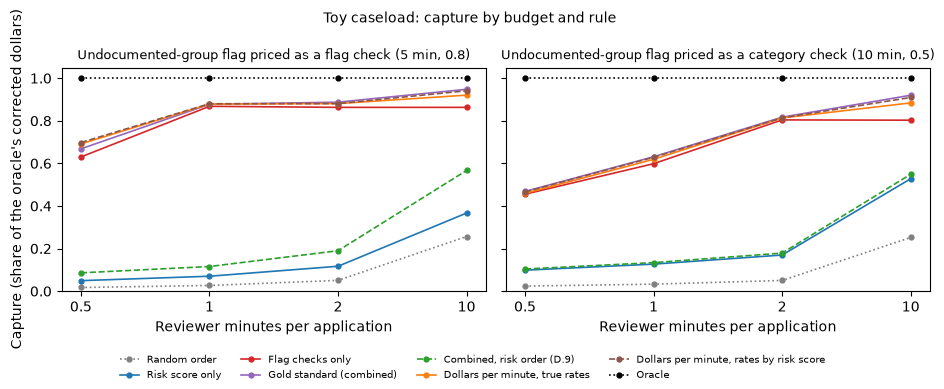

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
STYLE = {"Random order": ("grey", ":"), "Risk score only": ("tab:blue", "-"), "Flag checks only": ("tab:red", "-"),
         "Gold standard (combined)": ("tab:purple", "-"), "Combined, risk order (D.9)": ("tab:green", "--"),
         "Dollars per minute, true rates": ("tab:orange", "-"), "Dollars per minute, rates by risk score": ("tab:brown", "--"),
         "Oracle": ("black", ":")}
for ax, price_label in zip(axes, PRICES):
    for rule in RULE_ORDER:
        ax.plot(range(len(BUDGETS)), capture.loc[(price_label, rule), BUDGETS], marker="o", ms=3.5, lw=1.2,
                color=STYLE[rule][0], ls=STYLE[rule][1], label=rule)
    ax.set_xticks(range(len(BUDGETS)), [str(b) for b in BUDGETS])
    ax.set_xlabel("Reviewer minutes per application")
    ax.set_title(f"Undocumented-group flag priced as a {price_label}", fontsize=9)
axes[0].set_ylabel("Capture (share of the oracle's corrected dollars)")
axes[0].set_ylim(0, 1.05)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=7, frameon=False)
fig.suptitle("Toy caseload: capture by budget and rule", fontsize=10)
fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.savefig(OUT / "4d-capture-by-budget.svg")

### 4e. Undocumented-group flag priced both ways

The same caseloads, flags and luck, with a flag on an undocumented fact group priced first as a flag check (5 minutes, success 0.8) and then as a category check (10 minutes, success 0.5). Rank 1 is the rule with the highest capture at that budget (the oracle is left out of the ranking).

In [38]:
ranked = RULE_ORDER[:-1]
price_rows = []
for b in BUDGETS:
    cap = {p: capture.loc[p, b].reindex(ranked) for p in PRICES}
    rank_ = {p: cap[p].rank(ascending=False).astype(int) for p in PRICES}
    for rule in ranked:
        price_rows.append({"minutes per application": b, "rule": rule,
                           **{f"capture, {p}": round(cap[p][rule], 3) for p in PRICES},
                           **{f"rank, {p}": rank_[p][rule] for p in PRICES}})
both_prices = pd.DataFrame(price_rows).set_index(["minutes per application", "rule"])
p_flag, p_cat = list(PRICES)
both_prices["rank changes"] = both_prices[f"rank, {p_flag}"] != both_prices[f"rank, {p_cat}"]
both_prices["capture change"] = (both_prices[f"capture, {p_cat}"] - both_prices[f"capture, {p_flag}"]).round(3)
both_prices.to_csv(OUT / "4e-undocumented-flag-price.csv")
print("rule-by-budget cells whose rank changes with the price:", int(both_prices["rank changes"].sum()), "of", len(both_prices),
      "| rules involved:", ", ".join(sorted(set(both_prices.index[both_prices["rank changes"]].get_level_values("rule")))))
print("gold standard minus risk score only, capture:",
      {b: {p: round(float(capture.loc[(p, "Gold standard (combined)"), b] - capture.loc[(p, "Risk score only"), b]), 3) for p in PRICES} for b in BUDGETS})
both_prices

rule-by-budget cells whose rank changes with the price: 8 of 28 | rules involved: Dollars per minute, rates by risk score, Dollars per minute, true rates, Gold standard (combined)
gold standard minus risk score only, capture: {0.5: {'flag check (5 min, 0.8)': 0.619, 'category check (10 min, 0.5)': 0.37}, 1: {'flag check (5 min, 0.8)': 0.807, 'category check (10 min, 0.5)': 0.504}, 2: {'flag check (5 min, 0.8)': 0.771, 'category check (10 min, 0.5)': 0.647}, 10: {'flag check (5 min, 0.8)': 0.581, 'category check (10 min, 0.5)': 0.392}}


capture, flag check (5 min, 0.8)  \
minutes per application rule                                                                        
0.5                     Random order                                                        0.017   
                        Risk score only                                                     0.049   
                        Flag checks only                                                    0.630   
                        Gold standard (combined)                                            0.668   
                        Combined, risk order (D.9)                                          0.086   
                        Dollars per minute, true rates                                      0.691   
                        Dollars per minute, rates by risk score                             0.698   
1.0                     Random order                                                        0.027   
                        Risk score only                                                     0.070   
                        Flag checks only                                                    0.868   
                        Gold standard (combined)                                            0.877   
                        Combined, risk order (D.9)                                          0.116   
                        Dollars per minute, true rates                                      0.878   
                        Dollars per minute, rates by risk score                             0.880   
2.0                     Random order                                                        0.051   
                        Risk score only                                                     0.117   
                        Flag checks only                                                    0.863   
                        Gold standard (combined)                                            0.887   
                        Combined, risk order (D.9)                                          0.190   
                        Dollars per minute, true rates                                      0.881   
                        Dollars per minute, rates by risk score                             0.881   
10.0                    Random order                                                        0.257   
                        Risk score only                                                     0.367   
                        Flag checks only                                                    0.863   
                        Gold standard (combined)                                            0.948   
                        Combined, risk order (D.9)                                          0.567   
                        Dollars per minute, true rates                                      0.920   
                        Dollars per minute, rates by risk score                             0.941   

                                                                 capture, category check (10 min, 0.5)  \
minutes per application rule                                                                             
0.5                     Random order                                                             0.024   
                        Risk score only                                                          0.099   
                        Flag checks only                                                         0.455   
                        Gold standard (combined)                                                 0.468   
                        Combined, risk order (D.9)                                               0.104   
                        Dollars per minute, true rates                                           0.459   
                        Dollars per minute, rates by risk score                                  0.466   
1.0                     Random order                                            

### 4f. Capture vs dollars remaining

Error dollars remaining per 1,000 applications, beside capture. At one budget and one price every rule is divided by the same oracle figure, so capture and dollars remaining must agree on the order of rules. They can disagree across prices and across budgets, because the oracle's figure changes. The table counts both kinds of disagreement.

In [39]:
remaining_tbl = pd.concat({"capture": capture[BUDGETS], "error $ remaining per 1,000 applications": remaining[BUDGETS].round(0)}, axis=1)
remaining_tbl = remaining_tbl.reindex(RULE_ORDER, level=1)
flat = remaining_tbl.round(3)
flat.columns = [f"{measure}, {b} min" for measure, b in flat.columns]
flat.to_csv(OUT / "4f-capture-and-dollars-remaining.csv")

d_cap = capture.loc[p_cat, BUDGETS] - capture.loc[p_flag, BUDGETS]          # change when the price moves to the category price
d_rem = remaining.loc[p_cat, BUDGETS] - remaining.loc[p_flag, BUDGETS]
across_price = (d_cap > 1e-9) & (d_rem > 1e-9)                                # capture up although more dollars remain
across_budget = {p: (capture.loc[p, BUDGETS].diff(axis=1).iloc[:, 1:] < -1e-9) & (remaining.loc[p, BUDGETS].diff(axis=1).iloc[:, 1:] < -1e-9) for p in PRICES}
opposite = pd.Series({
    "error $ per 1,000 applications before review": round(TOTAL_ERROR / (REPS * N_TOY) * 1000),
    "rule-by-budget cells (oracle included)": int(across_price.size),
    "price moved to the category price: capture rises while more dollars remain": int(across_price.to_numpy().sum()),
    "  rules where that happens": ", ".join(sorted(across_price.index[across_price.any(axis=1)])) or "none",
    "budget raised one step: capture falls while fewer dollars remain, flag-check price": int(across_budget[p_flag].to_numpy().sum()),
    "budget raised one step: capture falls while fewer dollars remain, category-check price": int(across_budget[p_cat].to_numpy().sum()),
    "  rules where that happens (either price)": ", ".join(sorted(set(across_budget[p_flag].index[across_budget[p_flag].any(axis=1)]) | set(across_budget[p_cat].index[across_budget[p_cat].any(axis=1)]))) or "none",
    "same budget and price: rules ordered differently by capture and by dollars remaining": int(sum(
        (capture.loc[p, b].rank(ascending=False) != remaining.loc[p, b].rank()).sum() for p in PRICES for b in BUDGETS)),
})
opposite.to_csv(OUT / "4f-opposite-directions.csv", header=["value"])
display(opposite.to_frame("value"))
remaining_tbl.round(3)

,value
"error $ per 1,000 applications before review",34879
rule-by-budget cells (oracle included),32
price moved to the category price: capture rises while more dollars remain,4
rules where that happens,"Combined, risk order (D.9), Random order"
"budget raised one step: capture falls while fewer dollars remain, flag-check price",1
"budget raised one step: capture falls while fewer dollars remain, category-check price",1
rules where that happens (either price),Flag checks only
same budget and price: rules ordered differently by capture and by dollars remaining,0


capture  \
                                                                                0.5   
price of an undocumented-group flag rule                                              
category check (10 min, 0.5)        Random order                              0.024   
                                    Risk score only                           0.099   
                                    Flag checks only                          0.455   
                                    Gold standard (combined)                  0.468   
                                    Combined, risk order (D.9)                0.104   
                                    Dollars per minute, true rates            0.459   
                                    Dollars per minute, rates by risk score   0.466   
                                    Oracle                                    1.000   
flag check (5 min, 0.8)             Random order                              0.017   
                                    Risk score only                           0.049   
                                    Flag checks only                          0.630   
                                    Gold standard (combined)                  0.668   
                                    Combined, risk order (D.9)                0.086   
                                    Dollars per minute, true rates            0.691   
                                    Dollars per minute, rates by risk score   0.698   
                                    Oracle                                    1.000   

                                                                                    \
                                                                                 1   
price of an undocumented-group flag rule                                             
category check (10 min, 0.5)        Random order                             0.033   
                                    Risk score only                          0.127   
                                    Flag checks only                         0.598   
                                    Gold standard (combined)                 0.631   
                                    Combined, risk order (D.9)               0.134   
                                    Dollars per minute, true rates           0.619   
                                    Dollars per minute, rates by risk score  0.629   
                                    Oracle                                   1.000   
flag check (5 min, 0.8)             Random order                             0.027   
                                    Risk score only                          0.070   
                                    Flag checks only                         0.868   
                                    Gold standard (combined)                 0.877   
                                    Combined, risk order (D.9)               0.116   
                                    Dollars per minute, true rates           0.878   
                                    Dollars per minute, rates by risk score  0.880   
                                    Oracle                                   1.000   

                                                                                    \
                                                                                 2   
price of an undocumented-group flag rule                                             
category check (10 min, 0.5)        Random order                             0.050   
                                    Risk score only                          0.170   
                                    Flag checks only                         0.804   
                                    Gold standard (combined)                 0.817   
                                    Combined, risk order (D.9)               0.179   
                                    Dollars per minute, true rates           0.813   
             

## 5. Standard errors for RQ3

- **Question:** How many random category checks (n) are needed before filer-specific flag precision and miss rate are known well enough to help?
- **Expected:** None. An earlier rough figure: a rate near 3% needs about 500 checks to be known within 1.5 points.
- **Method:** Standard error of flag precision and miss rate from n checks that find an error half the time (`snapqc.calibration`); base rates from the 616 (`results/01-data-checks/3d-human-arm.csv`). Then filer-specific vs pooled rates with shrinkage, by simulation, for several sizes of the true gap between filers.
- **Result:** the earlier rough figure holds for checks that always find the error: 497 checks give +/- 1.5 points at a 3% rate. Checks that find the error half the time need 1,009. Base rates with one comparison household per error household and 80/80 flags: an error in 17.1% (earned), 15.5% (shelter), 10.6% (unearned) and 5.5% (utilities) of applications, so miss rates of 4.1%, 3.7%, 2.4% and 1.2%, and precision 0.8. With n spread over eight cells, the standard error of a cell's miss rate is 3.0 to 5.4 times the rate at n = 50, 0.76 to 1.34 times at 800, 0.38 to 0.67 times at 3,200 and 0.19 to 0.33 times at 12,800. Precision is known far worse, because few random checks land on a flag: its standard error is 95 to 167 points at n = 50, 12 to 21 points at 3,200 and 6 to 10 points at 12,800. Filer-specific rates against pooled rates: with no gap between filers pooled always wins; with a gap of 20 precision points and a doubled miss rate, filer-specific rates are at least 5% better from n = 3,200 (miss rate) and 6,400 (precision); with 40 points and a tripled miss rate, from 800; with 10 points and 1.5 times, from 12,800 for the miss rate and not within the grid for precision. The shrunk estimate is never more than 3.5% worse than pooled and is at least 5% better from 1,600 to 3,200 at the middle gap.
- **Mismatch:** none against the rough figure. Two results that bear on the grid. (1) Its largest value is not clearly enough: at n = 3,200 a cell's precision still has a standard error of 12 to 21 points, and filer-specific rates beat pooled rates only if the true gap is about 20 precision points and a doubled miss rate, or more. (2) The base rates depend on which errors can be flagged. Under Table B1 of the paper only 6% (earned), 5% (unearned), 34% (shelter) and 43% (utilities) of the 616's errors have a cause assumed detectable; then flags are rare and miss rates are 16.5%, 10.3%, 11.9% and 3.7%. At the 41-state caseload mix the 616's errors are in under 1% of applications and the earned miss rate is 0.12%, where 6,440 checks on unflagged groups in one cell give a standard error of half the rate.
- **Feeds:** `rq.md` RQ3 (the grid of n for the capture curve).
- **Options:** (a) the grid 50, 100, 200, 400, 800, 1,600, 3,200: the smallest values are too noisy to help, the largest is enough only for a large gap; (b) add 6,400 and 12,800 (1,067 and 2,133 reviewer hours of category checks); (c) aim half of each cell's checks at flagged fact groups: at n = 3,200 the precision standard error falls from 12 to 21 points to 6.9, and the earned miss rate's relative standard error rises from 0.38 to 0.49; (d) estimate precision from the outcomes of the flag checks a rule makes anyway (not computed here); (e) use the shrunk estimate wherever filer-specific rates are used.

### 5a. Base rates from the 616

What a random category check meets depends on how common errors are among the applications checked. Two mixes of applications are shown: the study's evaluation set with one comparison household per error household, and the 41-state caseload at its weighted share. Flags are 80/80 in the first block (every error can be flagged). The second block applies Table B1 of the paper: only causes the paper assumes detectable can be flagged; for the 616 that is cause 2 (incomplete or incorrect information provided).

Miss rate = share of unflagged fact groups that hold an error. Precision = share of flagged fact groups that hold one. With false flags added until 80% of flags are real, precision is 0.8 in every row and the flagged share equals the share of fact groups whose error is flagged, divided by 0.8.

In [40]:
from snapqc import calibration as cal

cause1 = full.loc[arm.index, "AGENCY1"]
arm4 = arm[arm.group.isin(qs.GROUPS)]
weight_share = (arm4.FYWGT.groupby(arm4.group).sum() / full.FYWGT[full.STATENAME.isin(SINGLE_SUA_STATES)].sum()).reindex(qs.GROUPS)
base = pd.DataFrame({
    "errors in the 616": arm4.group.value_counts().reindex(qs.GROUPS),
    "share with a cause assumed detectable (Table B1 of the paper)": (~cause1[arm4.index].isin(rs.NOT_DETECTABLE)).groupby(arm4.group).mean().reindex(qs.GROUPS).round(3),
})
MIXES = {"one comparison household per error household": base["errors in the 616"] / (2 * len(arm)),
         "41-state caseload (weighted share)": weight_share}
rate_rows = {}
for mix, prevalence in MIXES.items():
    for flags, recall in {"80/80 on every error": rs.FLAG_RECALL,
                          "80/80 on detectable causes only": rs.FLAG_RECALL * base.iloc[:, 1]}.items():
        flag_share = prevalence * recall / rs.FLAG_PRECISION
        rate_rows[(mix, flags)] = pd.DataFrame({
            "share of applications with an error in the group": prevalence, "flagged share of fact groups": flag_share,
            "precision": rs.FLAG_PRECISION * (flag_share > 0), "miss rate": prevalence * (1 - recall) / (1 - flag_share)})
base_rates = pd.concat(rate_rows, names=["mix of applications", "flags", "fact group"])
base_rates.round(5).to_csv(OUT / "5a-base-rates.csv")
print("causes of the 616 (AGENCY1):", cause1.value_counts().sort_index().to_dict(), "| outside the four groups:", len(arm) - len(arm4))
display(base.assign(**{"share of the 616": (base.iloc[:, 0] / len(arm)).round(3)}))
base_rates.round(4)

causes of the 616 (AGENCY1): {1.0: 253, 2.0: 120, 3.0: 87, 4.0: 153, 7.0: 3} | outside the four groups: 15


,errors in the 616,share with a cause assumed detectable (Table B1 of the paper),share of the 616
group,,,
earned,211,0.062,0.343
unearned,131,0.046,0.213
shelter,191,0.340,0.310
utilities,68,0.426,0.110


share of applications with an error in the group  \
mix of applications                          flags                           fact group                                                     
one comparison household per error household 80/80 on every error            earned                                                0.1713   
                                                                             unearned                                              0.1063   
                                                                             shelter                                               0.1550   
                                                                             utilities                                             0.0552   
                                             80/80 on detectable causes only earned                                                0.1713   
                                                                             unearned                                              0.1063   
                                                                             shelter                                               0.1550   
                                                                             utilities                                             0.0552   
41-state caseload (weighted share)           80/80 on every error            earned                                                0.0062   
                                                                             unearned                                              0.0044   
                                                                             shelter                                               0.0071   
                                                                             utilities                                             0.0026   
                                             80/80 on detectable causes only earned                                                0.0062   
                                                                             unearned                                              0.0044   
                                                                             shelter                                               0.0071   
                                                                             utilities                                             0.0026   

                                                                                         flagged share of fact groups  \
mix of applications                          flags                           fact group                                 
one comparison household per error household 80/80 on every error            earned                            0.1713   
                                                                             unearned                          0.1063   
                                                                             shelter                           0.1550   
                                                                             utilities                         0.0552   
                                             80/80 on detectable causes only earned                            0.0106   
                                                                             unearned                          0.0049   
                                                                             shelter                           0.0527   
                                                                             utilities                         0.0235   
41-state caseload (weighted share)           80/80 on every error            earned                            0.0062   
                                                                             unearned                          0.0044   
                                                                             shelter              

### 5b. Standard error by n

n is the total number of random category checks. They are spread over eight cells (two filers by four fact groups), so a cell gets n / 8. In a cell, the checks that land on an unflagged group estimate the miss rate and the checks that land on a flagged group estimate precision. A check finds an existing error with probability 0.5, so the estimate is (errors found) / (0.5 x checks) and its standard error is sqrt(q(1 - q) / checks) / 0.5 with q = 0.5 x rate.

First the earlier rough figure, then the table by n for the base rates of 5a (one comparison household per error household, 80/80 on every error).

In [41]:
MIX0, FLAGS0 = "one comparison household per error household", "80/80 on every error"
caseload_miss = float(rate_rows[("41-state caseload (weighted share)", FLAGS0)].at["earned", "miss rate"])
rough = pd.Series({
    "checks for +/- 1.5 points at a 3% rate, a check always finds the error": round(float(cal.n_for_half_width(0.03, 0.015, success=1.0))),
    "  expected (earlier rough figure)": "about 500",
    "the same, a check finds the error half the time": round(float(cal.n_for_half_width(0.03, 0.015))),
    "checks on flagged groups for +/- 10 points at precision 0.8, a check finds the error half the time": round(float(cal.n_for_half_width(0.8, 0.10))),
    f"checks on unflagged groups for a standard error of half the rate, miss rate {100 * caseload_miss:.2f}% (earned, 41-state caseload mix)": round(float(cal.n_for_half_width(caseload_miss, 0.5 * caseload_miss, z=1.0))),
})
N_GRID = [50, 100, 200, 400, 800, 1600, 3200, 6400, 12800]
CELLS = 8


def se_table(rates):
    """Standard errors by total n for one set of base rates (rows: fact groups)."""
    rows = []
    for n_total in N_GRID:
        for g in qs.GROUPS:
            n_flagged = n_total / CELLS * rates.at[g, "flagged share of fact groups"]
            rows.append({"total n": n_total, "fact group": g, "checks in the cell": n_total / CELLS,
                         "of which on flagged groups": round(n_flagged, 1),
                         "miss rate (%)": round(100 * rates.at[g, "miss rate"], 2),
                         "SE of miss rate (points)": round(100 * float(cal.rate_se(rates.at[g, "miss rate"], n_total / CELLS - n_flagged)), 2),
                         "SE of precision (points)": round(100 * float(cal.rate_se(rates.at[g, "precision"], n_flagged)), 1)})
    out = pd.DataFrame(rows).set_index(["total n", "fact group"])
    out["SE of miss rate / miss rate"] = (out["SE of miss rate (points)"] / out["miss rate (%)"]).round(2)
    return out


b0 = rate_rows[(MIX0, FLAGS0)]
se_by_n = se_table(b0)
pd.concat({flags: se_table(rates) for (mix, flags), rates in rate_rows.items() if mix == MIX0}, names=["flags"]).to_csv(OUT / "5b-se-by-n.csv")
display(rough.to_frame("value"))
pd.concat({"SE of miss rate (points)": se_by_n["SE of miss rate (points)"].unstack()[qs.GROUPS], "SE of precision (points)": se_by_n["SE of precision (points)"].unstack()[qs.GROUPS]}, axis=1)

,value
"checks for +/- 1.5 points at a 3% rate, a check always finds the error",497
expected (earlier rough figure),about 500
"the same, a check finds the error half the time",1009
"checks on flagged groups for +/- 10 points at precision 0.8, a check finds the error half the time",369
"checks on unflagged groups for a standard error of half the rate, miss rate 0.12% (earned, 41-state caseload mix)",6440


SE of miss rate (points)                             \
fact group                   earned unearned shelter utilities   
total n                                                          
50                            12.50     9.18   11.68      6.27   
100                            8.84     6.49    8.26      4.44   
200                            6.25     4.59    5.84      3.14   
400                            4.42     3.24    4.13      2.22   
800                            3.13     2.29    2.92      1.57   
1600                           2.21     1.62    2.06      1.11   
3200                           1.56     1.15    1.46      0.78   
6400                           1.11     0.81    1.03      0.55   
12800                          0.78     0.57    0.73      0.39   

           SE of precision (points)                             
fact group                   earned unearned shelter utilities  
total n                                                         
50                             94.7    120.2    99.5     166.8  
100                            67.0     85.0    70.4     118.0  
200                            47.4     60.1    49.8      83.4  
400                            33.5     42.5    35.2      59.0  
800                            23.7     30.0    24.9      41.7  
1600                           16.7     21.2    17.6      29.5  
3200                           11.8     15.0    12.4      20.9  
6400                            8.4     10.6     8.8      14.7  
12800                           5.9      7.5     6.2      10.4

In [42]:
# Check of the formula by simulation: one filer pair with equal rates, n = 800 and 3,200. The formula uses the expected
# number of flagged checks in a cell; the simulation draws it, clips estimates to [0, 1], and gives a cell with no
# flagged check the pooled estimate, so its precision figure is somewhat lower at small n.
P = np.tile(b0["precision"].to_numpy(), (2, 1))
M = np.tile(b0["miss rate"].to_numpy(), (2, 1))
F = np.tile(b0["flagged share of fact groups"].to_numpy(), (2, 1))
sim_rng = np.random.default_rng([SEED, 5])
mc_rows = []
for n_total in [800, 3200]:
    draws = cal.simulate_checks(sim_rng, n_total, P, M, F, reps=4000)
    for j, g in enumerate(qs.GROUPS):
        mc_rows.append({"total n": n_total, "fact group": g,
                        "SE of miss rate, formula": se_by_n.at[(n_total, g), "SE of miss rate (points)"],
                        "SE of miss rate, simulated": round(100 * draws["miss_rate"]["specific"][:, 0, j].std(), 2),
                        "SE of precision, formula": se_by_n.at[(n_total, g), "SE of precision (points)"],
                        "SE of precision, simulated": round(100 * draws["precision"]["specific"][:, 0, j].std(), 1)})
se_check = pd.DataFrame(mc_rows).set_index(["total n", "fact group"])
se_check.to_csv(OUT / "5b-se-formula-vs-simulation.csv")
se_check

SE of miss rate, formula  SE of miss rate, simulated  \
total n fact group                                                         
800     earned                          3.13                        3.15   
        unearned                        2.29                        2.32   
        shelter                         2.92                        2.96   
        utilities                       1.57                        1.58   
3200    earned                          1.56                        1.55   
        unearned                        1.15                        1.14   
        shelter                         1.46                        1.47   
        utilities                       0.78                        0.79   

                    SE of precision, formula  SE of precision, simulated  
total n fact group                                                        
800     earned                          23.7                        19.7  
        unearned                        30.0                        24.7  
        shelter                         24.9                        20.6  
        utilities                       41.7                        32.7  
3200    earned                          11.8                        11.3  
        unearned                        15.0                        14.1  
        shelter                         12.4                        11.8  
        utilities                       20.9                        18.1

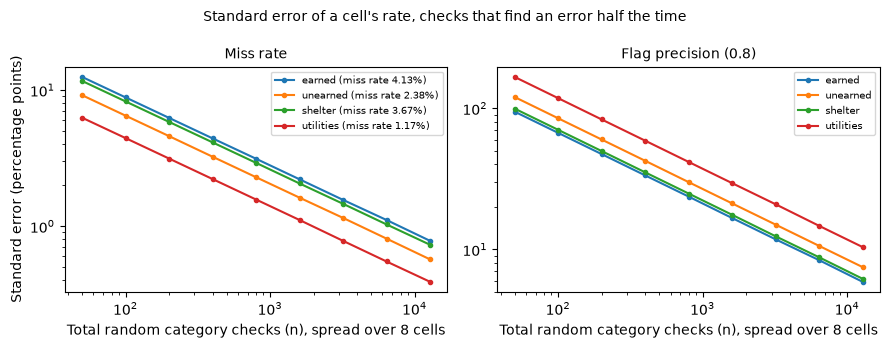

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for g, color in zip(qs.GROUPS, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    axes[0].plot(N_GRID, se_by_n.xs(g, level=1)["SE of miss rate (points)"], marker="o", ms=3, color=color, label=f"{g} (miss rate {se_by_n.at[(50, g), 'miss rate (%)']}%)")
    axes[1].plot(N_GRID, se_by_n.xs(g, level=1)["SE of precision (points)"], marker="o", ms=3, color=color, label=g)
for ax, title in zip(axes, ["Miss rate", "Flag precision (0.8)"]):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Total random category checks (n), spread over 8 cells")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7)
axes[0].set_ylabel("Standard error (percentage points)")
fig.suptitle("Standard error of a cell's rate, checks that find an error half the time", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "5b-se-by-n.svg")

### 5c. Filer-specific vs pooled, with shrinkage

Two filers. The human filer has the base rates of 5b. The AI filer's true rates differ by a gap that is not known before the experiment, so several gaps are tried: precision lower by 0, 10, 20 and 40 points, with the miss rate 1, 1.5, 2 and 3 times the human filer's. For each total n, 2,000 calibration samples are drawn and each cell's rate is estimated three ways (`snapqc.calibration.estimate`): filer-specific, pooled over the two filers, and the filer-specific estimate shrunk toward the pooled one. The error measure is the root mean squared error over the eight cells, in percentage points.

The pooled estimate is wrong by half the gap however large n is; the filer-specific estimate is unbiased but noisy. Where the two cross is the n at which filer-specific rates start to pay.

In [44]:
GAPS = {"no gap": (0.0, 1.0), "precision -10 points, miss rate x1.5": (0.10, 1.5),
        "precision -20 points, miss rate x2": (0.20, 2.0), "precision -40 points, miss rate x3": (0.40, 3.0)}
REPS_5C = 2000
gap_rng = np.random.default_rng([SEED, 53])
rmse_rows = []
for gap, (d_precision, miss_ratio) in GAPS.items():
    P2 = np.vstack([b0["precision"].to_numpy(), b0["precision"].to_numpy() - d_precision])
    M2 = np.vstack([b0["miss rate"].to_numpy(), b0["miss rate"].to_numpy() * miss_ratio])
    for n_total in N_GRID:
        draws = cal.simulate_checks(gap_rng, n_total, P2, M2, F, reps=REPS_5C)
        for rate, truth in [("precision", P2), ("miss rate", M2)]:
            est = draws[rate.replace(" ", "_")]
            rmse_rows.append({"gap between filers": gap, "rate": rate, "total n": n_total,
                              **{k: 100 * float(np.sqrt(((est[k] - truth) ** 2).mean())) for k in ("specific", "pooled", "shrunk")}})
rmse = pd.DataFrame(rmse_rows).set_index(["gap between filers", "rate", "total n"]).rename(
    columns={"specific": "filer-specific", "pooled": "pooled", "shrunk": "shrunk"}).sort_index()
rmse.round(2).to_csv(OUT / "5c-rmse-by-n.csv")


def from_n(ratio, below):
    """Smallest n in the grid from which the ratio stays below `below` at every larger n."""
    ok = (ratio < below).to_numpy()[::-1].cumprod()[::-1].astype(bool)
    return str(ratio.index[ok][0]) if ok.any() else f"above {N_GRID[-1]}"


def gap_floor(gap, rate):
    """Error of the pooled rate with no sampling noise: root mean square distance of the true rates from their filer average."""
    d_precision, miss_ratio = GAPS[gap]
    truth = np.vstack([b0["precision"], b0["precision"] - d_precision]) if rate == "precision" else np.vstack([b0["miss rate"], b0["miss rate"] * miss_ratio])
    return 100 * float(np.sqrt(((truth - truth.mean(0)) ** 2).mean()))


crossing = pd.DataFrame({
    (gap, rate): {
        "pooled error with no sampling noise (points)": round(gap_floor(gap, rate), 2),
        "filer-specific at least 5% better than pooled from n": from_n(rmse.loc[(gap, rate), "filer-specific"] / rmse.loc[(gap, rate), "pooled"], 0.95),
        "shrunk at least 5% better than pooled from n": from_n(rmse.loc[(gap, rate), "shrunk"] / rmse.loc[(gap, rate), "pooled"], 0.95),
        "largest n where filer-specific is worse than pooled": str(max([n for n in N_GRID if rmse.at[(gap, rate, n), "filer-specific"] > rmse.at[(gap, rate, n), "pooled"]], default="none")),
        "worst shrunk / pooled at any n": f"{float((rmse.loc[(gap, rate), 'shrunk'] / rmse.loc[(gap, rate), 'pooled']).max()):.3f}",
    } for gap in GAPS for rate in ("precision", "miss rate")}).T
crossing.index.names = ["gap between filers", "rate"]
crossing.to_csv(OUT / "5c-crossing-n.csv")
display(crossing)
rmse.loc[list(GAPS)[2]].round(2).unstack("total n")

pooled error with no sampling noise (points)  \
gap between filers                   rate                                                     
no gap                               precision                                          0.0   
                                     miss rate                                          0.0   
precision -10 points, miss rate x1.5 precision                                          5.0   
                                     miss rate                                         0.77   
precision -20 points, miss rate x2   precision                                         10.0   
                                     miss rate                                         1.53   
precision -40 points, miss rate x3   precision                                         20.0   
                                     miss rate                                         3.06   

                                               filer-specific at least 5% better than pooled from n  \
gap between filers                   rate                                                             
no gap                               precision                                        above 12800     
                                     miss rate                                        above 12800     
precision -10 points, miss rate x1.5 precision                                        above 12800     
                                     miss rate                                              12800     
precision -20 points, miss rate x2   precision                                               6400     
                                     miss rate                                               3200     
precision -40 points, miss rate x3   precision                                                800     
                                     miss rate                                                800     

                                               shrunk at least 5% better than pooled from n  \
gap between filers                   rate                                                     
no gap                               precision                                  above 12800   
                                     miss rate                                  above 12800   
precision -10 points, miss rate x1.5 precision                                        12800   
                                     miss rate                                         6400   
precision -20 points, miss rate x2   precision                                         3200   
                                     miss rate                                         1600   
precision -40 points, miss rate x3   precision                                          800   
                                     miss rate                                          800   

                                               largest n where filer-specific is worse than pooled  \
gap between filers                   rate                                                            
no gap                               precision                                              12800    
                                     miss rate                                              12800    
precision -10 points, miss rate x1.5 precision                                              12800    
                                     miss rate                                               3200    
precision -20 points, miss rate x2   precision                                               1600    
                                     miss rate                                               1600    
precision -40 points, miss rate x3   precision                                                400    
                                     miss rate                                                400    

                                               worst shrunk / pooled at any n  
gap between f

filer-specific                                                   \
total n            50     100    200    400    800    1600   3200   6400    
rate                                                                        
miss rate          13.05   9.30   6.43   4.43   3.12   2.20   1.55   1.10   
precision          60.15  53.78  45.51  35.58  26.32  19.35  14.31  10.36   

                pooled  ...        shrunk                                     \
total n   12800  50     ...  12800  50     100    200    400    800    1600    
rate                    ...                                                    
miss rate  0.78   9.13  ...   1.63   9.27   6.63   4.80   3.49   2.63   2.01   
precision  7.38  57.69  ...  11.30  57.68  48.01  37.22  28.75  21.87  17.10   

                               
total n    3200   6400  12800  
rate                           
miss rate   1.56   1.18  0.84  
precision  13.40  10.20  7.52  

[2 rows x 27 columns]

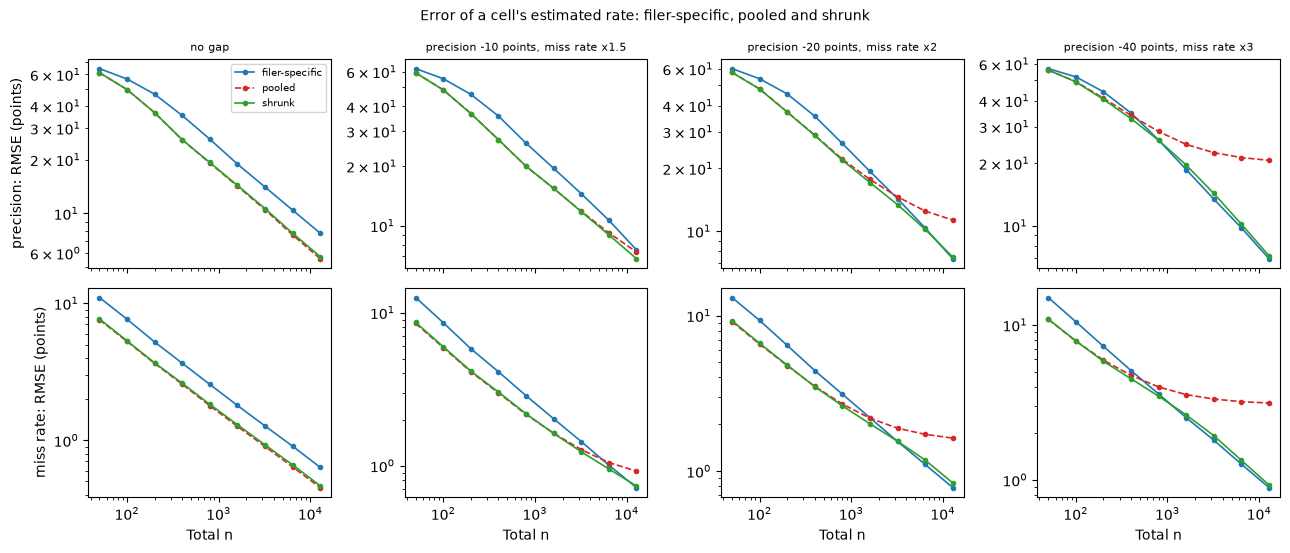

In [45]:
fig, axes = plt.subplots(2, len(GAPS), figsize=(13, 5.6), sharex=True)
for j, gap in enumerate(GAPS):
    for i, rate in enumerate(["precision", "miss rate"]):
        ax = axes[i, j]
        for k, color, ls in [("filer-specific", "tab:blue", "-"), ("pooled", "tab:red", "--"), ("shrunk", "tab:green", "-")]:
            ax.plot(N_GRID, rmse.loc[(gap, rate), k], color=color, ls=ls, marker="o", ms=3, lw=1.2, label=k)
        ax.set_xscale("log")
        ax.set_yscale("log")
        if i == 0:
            ax.set_title(gap, fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{rate}: RMSE (points)")
        if i == 1:
            ax.set_xlabel("Total n")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Error of a cell's estimated rate: filer-specific, pooled and shrunk", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "5c-rmse-by-n.svg")

### 5d. Proposed grid of n

The grid has to start where estimates are too noisy to help and end where they are clearly good enough. The table puts each candidate n beside what 5b and 5c say about it. "Reviewer hours" is n category checks at 10 minutes each. The last two rows show one alternative: half of each cell's checks aimed at flagged fact groups, which trades precision error against miss-rate error.

In [46]:
mid_gap, big_gap = list(GAPS)[2], list(GAPS)[3]
grid = pd.DataFrame({
    "checks per cell": [n / CELLS for n in N_GRID],
    "reviewer hours": [n * rs.CAT_MINUTES / 60 for n in N_GRID],
    "SE of miss rate / miss rate, largest group (earned)": [se_by_n.at[(n, "earned"), "SE of miss rate / miss rate"] for n in N_GRID],
    "SE of miss rate / miss rate, smallest group (utilities)": [se_by_n.at[(n, "utilities"), "SE of miss rate / miss rate"] for n in N_GRID],
    "SE of precision, earned (points)": [se_by_n.at[(n, "earned"), "SE of precision (points)"] for n in N_GRID],
    "SE of precision, utilities (points)": [se_by_n.at[(n, "utilities"), "SE of precision (points)"] for n in N_GRID],
    f"miss rate RMSE, filer-specific / pooled ({mid_gap})": [rmse.at[(mid_gap, "miss rate", n), "filer-specific"] / rmse.at[(mid_gap, "miss rate", n), "pooled"] for n in N_GRID],
    f"precision RMSE, filer-specific / pooled ({mid_gap})": [rmse.at[(mid_gap, "precision", n), "filer-specific"] / rmse.at[(mid_gap, "precision", n), "pooled"] for n in N_GRID],
    f"precision RMSE, shrunk / pooled ({mid_gap})": [rmse.at[(mid_gap, "precision", n), "shrunk"] / rmse.at[(mid_gap, "precision", n), "pooled"] for n in N_GRID],
    f"precision RMSE, filer-specific / pooled ({big_gap})": [rmse.at[(big_gap, "precision", n), "filer-specific"] / rmse.at[(big_gap, "precision", n), "pooled"] for n in N_GRID],
    "half the checks on flagged groups: SE of precision, any group (points)": [100 * float(cal.rate_se(rs.FLAG_PRECISION, n / CELLS / 2)) for n in N_GRID],
    "half the checks on flagged groups: SE of miss rate / miss rate, earned": [float(cal.rate_se(b0.at["earned", "miss rate"], n / CELLS / 2)) / b0.at["earned", "miss rate"] for n in N_GRID],
}, index=pd.Index(N_GRID, name="total n")).round(2)
grid.to_csv(OUT / "5d-grid-of-n.csv")
grid.T

total n,50,100,200,400,800,1600,3200,6400,12800
checks per cell,6.25,12.50,25.00,50.00,100.00,200.00,400.00,800.00,1600.00
reviewer hours,8.33,16.67,33.33,66.67,133.33,266.67,533.33,1066.67,2133.33
"SE of miss rate / miss rate, largest group (earned)",3.03,2.14,1.51,1.07,0.76,0.54,0.38,0.27,0.19
"SE of miss rate / miss rate, smallest group (utilities)",5.36,3.79,2.68,1.90,1.34,0.95,0.67,0.47,0.33
"SE of precision, earned (points)",94.70,67.00,47.40,33.50,23.70,16.70,11.80,8.40,5.90
"SE of precision, utilities (points)",166.80,118.00,83.40,59.00,41.70,29.50,20.90,14.70,10.40
"miss rate RMSE, filer-specific / pooled (precision -20 points, miss rate x2)",1.43,1.42,1.35,1.26,1.16,1.01,0.82,0.64,0.48
"precision RMSE, filer-specific / pooled (precision -20 points, miss rate x2)",1.04,1.12,1.22,1.23,1.19,1.09,0.98,0.83,0.65
"precision RMSE, shrunk / pooled (precision -20 points, miss rate x2)",1.00,1.00,1.00,1.00,0.99,0.97,0.92,0.82,0.67
"precision RMSE, filer-specific / pooled (precision -40 points, miss rate x3)",1.02,1.05,1.07,1.03,0.91,0.76,0.60,0.46,0.34
